# 02. Feature Engineering, Machine Learning Models & Evaluation (Review 2)

**Course:** BCP308 Community Project (Mini Project) | **Team:** B-7  
**Project:** Forecasting Household Appliance Energy Use  
**Dataset:** UCI Appliances Energy Prediction (`data/energydata_complete.csv`)  
**Horizons:** `h = 1` (10 minutes ahead) and `h = 6` (1 hour ahead)

### Anti-Leakage & Evaluation Ground Rules
1. **Strict Origin Constraint:** Predict `Appliances(t + h)` using only information available at or before time `t`.
2. **Shared Feature Logic:** All features are generated via `src/features.py` (reused identically by `app.py`).
3. **Chronological Split Only:** 70% Train (`13,814` rows) / 15% Validation (`2,960` rows) / 15% Test (`2,961` rows), matching Review 1.
4. **Validation-Only Selection:** Hyperparameters and target transforms (`raw` vs `log1p`) are chosen strictly by validation MAE; the test set is evaluated only after selection.
5. **Production Exclusions:** `lights`, `rv1`, and `rv2` are excluded from all production models (`rv1`/`rv2` are tested separately in Section 11 as a negative-control diagnostic).


## Section 1: Imports and Configuration


In [1]:
import sys
import json
from pathlib import Path
from datetime import datetime, timezone

# Ensure project root is on sys.path whether running locally or in Colab
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.features import (
    FORBIDDEN_PRODUCTION_COLS,
    MAX_LOOKBACK_STEPS,
    build_features,
    chronological_split_indices,
    load_and_validate_data,
    prepare_forecast_datasets,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = PROJECT_ROOT / "data" / "energydata_complete.csv"
FIG_DIR = PROJECT_ROOT / "figures"
OUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"

FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 150
sns.set_style("whitegrid")

print(f"Project root: {PROJECT_ROOT}")
print(f"Python:       {sys.version.split()[0]}")
print(f"pandas:       {pd.__version__} | numpy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__} | lightgbm: {lgb.__version__}")


Project root: /home/unhealthycoder/mini-project--3rd-SEM
Python:       3.14.10
pandas:       3.1.1 | numpy: 2.5.5
scikit-learn: 1.9.1 | lightgbm: 4.7.0


## Section 2: Data Loading & Integrity Verification


In [2]:
df = load_and_validate_data(DATA_PATH)
baseline_df = pd.read_csv(OUT_DIR / "baseline_results.csv")

time_diffs = df["date"].diff().dropna()
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print(f"Date range: {df['date'].min()} -> {df['date'].max()}")
print(f"Monotonic increasing: {df['date'].is_monotonic_increasing}")
print(f"Total missing values: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())} | Duplicate timestamps: {int(df['date'].duplicated().sum())}")
print(f"Strictly 10-minute spacing: {bool((time_diffs == pd.Timedelta(minutes=10)).all())}")

display(baseline_df)


Rows: 19,735 | Columns: 29
Date range: 2016-01-11 17:00:00 -> 2016-05-27 18:00:00
Monotonic increasing: True
Total missing values: 0
Duplicate rows: 0 | Duplicate timestamps: 0
Strictly 10-minute spacing: True


,Horizon,Baseline,Val_MAE,Val_RMSE,Val_R2,Test_MAE,Test_RMSE,Test_R2
0,h=1 (10-min),Persistence,26.16,66.44,0.4813,26.75,66.85,0.4590
1,h=1 (10-min),Same Time Yesterday,53.32,115.40,-0.5647,52.51,109.49,-0.4513
2,h=1 (10-min),Train-Mean,53.98,92.41,-0.0034,52.83,90.90,-0.0004
3,h=1 (10-min),"Mean by (hour, is_weekend)",48.51,87.23,0.1060,47.90,85.75,0.1098
4,h=6 (1-hour),Persistence,51.58,111.45,-0.4609,46.37,101.76,-0.2520
5,h=6 (1-hour),Same Time Yesterday,53.24,115.38,-0.5657,52.59,109.58,-0.4519
6,h=6 (1-hour),Train-Mean,53.94,92.38,-0.0036,52.85,90.96,-0.0004
7,h=6 (1-hour),"Mean by (hour, is_weekend)",48.47,87.21,0.1057,47.97,85.82,0.1095


## Section 3: Feature Engineering (`src/features.py`)

We import `build_features` directly from `src/features.py` so training, evaluation, and the Streamlit app share a single code path:
- **Time:** `hour`, `hour_sin`, `hour_cos`, `day_of_week`, `is_weekend`.
- **Consumption lags:** `appliance_lag_0` (at `t`), `lag_1`, `lag_2`, `lag_3`, `lag_6` (1h), `lag_144` (24h).
- **Rolling means:** `appliance_roll_mean_1h` (6 steps), `3h` (18 steps), `6h` (36 steps) — computed on `Appliances.shift(1)` over `[t-w .. t-1]`.
- **Context:** `indoor_temp_mean` (mean of `T1..T5, T7..T9`), `indoor_rh_mean`, `temp_diff_in_out` (`indoor_temp_mean - T_out`), `temp_diff_in_t6` (`indoor_temp_mean - T6`), `rh_diff_in_out`, plus indoor sensors and outdoor weather (`T6`, `RH_6`, `T_out`, `Press_mm_hg`, `RH_out`, `Windspeed`, `Visibility`, `Tdewpoint`).
- **Exclusions:** `lights`, `rv1`, and `rv2` are excluded from the production matrix.


In [3]:
X_preview = build_features(df, include_random_controls=False)
print(f"Feature matrix shape: {X_preview.shape}")
print(f"Number of production features: {X_preview.shape[1]}")
print("Forbidden columns present:", set(FORBIDDEN_PRODUCTION_COLS) & set(X_preview.columns))
print("\nFeature list:")
for idx, col in enumerate(X_preview.columns, start=1):
    print(f"  {idx:2d}. {col}")

display(X_preview.dropna().head(3))


Feature matrix shape: (19735, 43)
Number of production features: 43
Forbidden columns present: set()

Feature list:
   1. hour
   2. hour_sin
   3. hour_cos
   4. day_of_week
   5. is_weekend
   6. appliance_lag_0
   7. appliance_lag_1
   8. appliance_lag_2
   9. appliance_lag_3
  10. appliance_lag_6
  11. appliance_lag_144
  12. appliance_roll_mean_1h
  13. appliance_roll_mean_3h
  14. appliance_roll_mean_6h
  15. indoor_temp_mean
  16. indoor_rh_mean
  17. temp_diff_in_out
  18. temp_diff_in_t6
  19. rh_diff_in_out
  20. T1
  21. T2
  22. T3
  23. T4
  24. T5
  25. T7
  26. T8
  27. T9
  28. RH_1
  29. RH_2
  30. RH_3
  31. RH_4
  32. RH_5
  33. RH_7
  34. RH_8
  35. RH_9
  36. T6
  37. RH_6
  38. T_out
  39. Press_mm_hg
  40. RH_out
  41. Windspeed
  42. Visibility
  43. Tdewpoint


,hour,hour_sin,hour_cos,day_of_week,is_weekend,appliance_lag_0,appliance_lag_1,appliance_lag_2,appliance_lag_3,appliance_lag_6,...,RH_8,RH_9,T6,RH_6,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
144,17.0,-0.965926,-0.258819,1.0,0.0,60.0,40.0,40.0,40.0,30.0,...,45.790000,43.260,6.156667,76.893333,6.500000,744.200000,75.000000,7.0,29.000000,2.300000
145,17.0,-0.965926,-0.258819,1.0,0.0,60.0,60.0,40.0,40.0,40.0,...,45.808333,43.200,6.090000,77.560000,6.316667,744.283333,76.666667,7.0,30.833333,2.433333
146,17.0,-0.965926,-0.258819,1.0,0.0,210.0,60.0,60.0,40.0,50.0,...,45.900000,43.145,6.090000,77.995000,6.133333,744.366667,78.333333,7.0,32.666667,2.566667


## Section 4 & Section 5: Forecast Targets & Chronological 70/15/15 Split

- Targets are defined per split via `target_h = Appliances.shift(-h)` for `h = 1` (10 min) and `h = 6` (1 hour).
- Backward-looking lags/rolling means retain historical context across split boundaries (so validation and test keep the exact `2,960 - h` and `2,961 - h` evaluation rows from Review 1).
- Targets never cross split boundaries (`meta_train.target_date.max() <= meta_val.date.min()`).


In [4]:
datasets = {}
for h in (1, 6):
    ds = prepare_forecast_datasets(df, horizon=h, include_random_controls=False)
    datasets[h] = ds
    print(f"=== Horizon h={h} ({h*10} min ahead) ===")
    for split in ("train", "val", "test"):
        meta = ds[f"meta_{split}"]
        X_s = ds[f"X_{split}"]
        print(
            f"  {split:5s}: X={X_s.shape}, "
            f"origin=[{meta['date'].min()} -> {meta['date'].max()}], "
            f"target=[{meta['target_date'].min()} -> {meta['target_date'].max()}]"
        )
    assert ds["meta_train"]["target_date"].max() <= ds["meta_val"]["date"].min()
    assert ds["meta_val"]["target_date"].max() <= ds["meta_test"]["date"].min()

# Spot-check target alignment on first 3 test rows for h=1 and h=6
for h in (1, 6):
    print(f"\nTarget alignment spot check (Test, h={h}):")
    display(datasets[h]["meta_test"].head(3))


=== Horizon h=1 (10 min ahead) ===
  train: X=(13669, 43), origin=[2016-01-12 17:00:00 -> 2016-04-16 15:00:00], target=[2016-01-12 17:10:00 -> 2016-04-16 15:10:00]
  val  : X=(2959, 43), origin=[2016-04-16 15:20:00 -> 2016-05-07 04:20:00], target=[2016-04-16 15:30:00 -> 2016-05-07 04:30:00]
  test : X=(2960, 43), origin=[2016-05-07 04:40:00 -> 2016-05-27 17:50:00], target=[2016-05-07 04:50:00 -> 2016-05-27 18:00:00]
=== Horizon h=6 (60 min ahead) ===
  train: X=(13664, 43), origin=[2016-01-12 17:00:00 -> 2016-04-16 14:10:00], target=[2016-01-12 18:00:00 -> 2016-04-16 15:10:00]
  val  : X=(2954, 43), origin=[2016-04-16 15:20:00 -> 2016-05-07 03:30:00], target=[2016-04-16 16:20:00 -> 2016-05-07 04:30:00]
  test : X=(2955, 43), origin=[2016-05-07 04:40:00 -> 2016-05-27 17:00:00], target=[2016-05-07 05:40:00 -> 2016-05-27 18:00:00]

Target alignment spot check (Test, h=1):


,date,target_date,Appliances_t,target
0,2016-05-07 04:40:00,2016-05-07 04:50:00,60.0,60.0
1,2016-05-07 04:50:00,2016-05-07 05:00:00,60.0,60.0
2,2016-05-07 05:00:00,2016-05-07 05:10:00,60.0,50.0



Target alignment spot check (Test, h=6):


,date,target_date,Appliances_t,target
0,2016-05-07 04:40:00,2016-05-07 05:40:00,60.0,50.0
1,2016-05-07 04:50:00,2016-05-07 05:50:00,60.0,50.0
2,2016-05-07 05:00:00,2016-05-07 06:00:00,60.0,40.0


## Section 6 & Section 7: Initial ML Models & Target Transformation (`raw` vs `log1p`)

For each horizon (`h=1`, `h=6`), we compare three model families:
1. **Ridge Regression (validation-selected `alpha`):** `Pipeline` with train-only `StandardScaler` and `Ridge`, selecting `alpha` from `[0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0]` via **validation MAE** (so Ridge is validation-regularized even in the initial comparison).
2. **Random Forest Regressor:** Conservative fixed settings (`n_estimators=150`, `max_depth=12`, `min_samples_leaf=5`, `max_features="sqrt"`).
3. **LightGBM Regressor:** Conservative defaults (`n_estimators=1000`, `learning_rate=0.03`, `num_leaves=31`, `min_child_samples=20`) with validation early stopping (`50` rounds).

Every model is trained on **both**:
- `raw`: directly on `Appliances` (Wh).
- `log1p`: on `np.log1p(Appliances)`, inverted via `np.clip(np.expm1(y_pred_log), 0.0, None)` and evaluated strictly in original Wh.


In [5]:
def compute_metrics(y_true, y_pred):
    y_true_arr = np.asarray(y_true, dtype=float)
    y_pred_arr = np.asarray(y_pred, dtype=float)
    mae = float(mean_absolute_error(y_true_arr, y_pred_arr))
    rmse = float(np.sqrt(mean_squared_error(y_true_arr, y_pred_arr)))
    r2 = float(r2_score(y_true_arr, y_pred_arr))
    return {"MAE": mae, "RMSE": rmse, "R2": r2}


def invert_predictions(preds, transform_name):
    preds_arr = np.asarray(preds, dtype=float)
    if transform_name == "log1p":
        preds_arr = np.expm1(preds_arr)
    return np.clip(preds_arr, 0.0, None)


def fit_and_predict_model(model_family, transform_name, X_train, y_train, X_val, y_val, params=None):
    y_tr_fit = np.log1p(y_train) if transform_name == "log1p" else y_train.astype(float)
    y_va_fit = np.log1p(y_val) if transform_name == "log1p" else y_val.astype(float)

    if model_family == "Ridge":
        best_alpha = None
        best_val_mae = np.inf
        best_pipe = None
        alpha_grid = [0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0]
        if params and "alpha" in params:
            alpha_grid = [params["alpha"]]
        for alpha in alpha_grid:
            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge(alpha=alpha, random_state=RANDOM_STATE)),
            ])
            pipe.fit(X_train, y_tr_fit)
            val_pred = invert_predictions(pipe.predict(X_val), transform_name)
            val_mae = mean_absolute_error(y_val, val_pred)
            if val_mae < best_val_mae:
                best_val_mae = val_mae
                best_alpha = alpha
                best_pipe = pipe
        return best_pipe, {"alpha": best_alpha}

    elif model_family == "Random Forest":
        cfg = dict(
            n_estimators=150,
            max_depth=12,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        if params:
            cfg.update(params)
        rf = RandomForestRegressor(**cfg)
        rf.fit(X_train, y_tr_fit)
        return rf, cfg

    elif model_family == "LightGBM":
        cfg = dict(
            n_estimators=1000,
            learning_rate=0.03,
            num_leaves=31,
            min_child_samples=20,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            objective="regression",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1,
        )
        if params:
            cfg.update(params)
        gbm = LGBMRegressor(**cfg)
        gbm.fit(
            X_train,
            y_tr_fit,
            eval_set=[(X_val, y_va_fit)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
        )
        cfg["best_iteration_"] = int(gbm.best_iteration_ or cfg["n_estimators"])
        return gbm, cfg

    raise ValueError(f"Unknown model family: {model_family}")


# Lookup Review 1 Persistence MAEs for skill score calculation
persist_lookup = {}
for h_val, h_label in [(1, "h=1 (10-min)"), (6, "h=6 (1-hour)")]:
    row = baseline_df[(baseline_df["Horizon"] == h_label) & (baseline_df["Baseline"] == "Persistence")].iloc[0]
    persist_lookup[h_val] = {"Val_MAE": float(row["Val_MAE"]), "Test_MAE": float(row["Test_MAE"])}

trained_models = {1: {}, 6: {}}
ml_records = []

for h in (1, 6):
    h_label = "h=1 (10-min)" if h == 1 else "h=6 (1-hour)"
    ds = datasets[h]
    X_train, y_train = ds["X_train"], ds["y_train"]
    X_val, y_val = ds["X_val"], ds["y_val"]
    X_test, y_test = ds["X_test"], ds["y_test"]

    for family in ("Ridge", "Random Forest", "LightGBM"):
        for transform_name in ("raw", "log1p"):
            model, used_params = fit_and_predict_model(
                family, transform_name, X_train, y_train, X_val, y_val
            )
            val_pred = invert_predictions(model.predict(X_val), transform_name)
            test_pred = invert_predictions(model.predict(X_test), transform_name)

            val_m = compute_metrics(y_val, val_pred)
            test_m = compute_metrics(y_test, test_pred)

            key = (family, transform_name)
            trained_models[h][key] = {
                "model": model,
                "params": used_params,
                "val_pred": val_pred,
                "test_pred": test_pred,
                "val_metrics": val_m,
                "test_metrics": test_m,
            }

            if family == "Ridge":
                print(f"[h={h}] Ridge ({transform_name}) validation-selected alpha = {used_params['alpha']}")

            ml_records.append({
                "Horizon": h_label,
                "Model": family,
                "Target_Transform": transform_name,
                "Category": "ML (Val-Alpha)" if family == "Ridge" else "ML",
                "Val_MAE": round(val_m["MAE"], 2),
                "Val_RMSE": round(val_m["RMSE"], 2),
                "Val_R2": round(val_m["R2"], 4),
                "Val_Skill_vs_Persist": round(1.0 - val_m["MAE"] / persist_lookup[h]["Val_MAE"], 4),
                "Test_MAE": round(test_m["MAE"], 2),
                "Test_RMSE": round(test_m["RMSE"], 2),
                "Test_R2": round(test_m["R2"], 4),
                "Test_Skill_vs_Persist": round(1.0 - test_m["MAE"] / persist_lookup[h]["Test_MAE"], 4),
            })

initial_ml_df = pd.DataFrame(ml_records)
display(initial_ml_df)


[h=1] Ridge (raw) validation-selected alpha = 100.0
[h=1] Ridge (log1p) validation-selected alpha = 1000.0


/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[h=6] Ridge (raw) validation-selected alpha = 1000.0
[h=6] Ridge (log1p) validation-selected alpha = 1000.0


/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,Horizon,Model,Target_Transform,Category,Val_MAE,Val_RMSE,Val_R2,Val_Skill_vs_Persist,Test_MAE,Test_RMSE,Test_R2,Test_Skill_vs_Persist
0,h=1 (10-min),Ridge,raw,ML (Val-Alpha),26.47,59.91,0.5782,-0.0119,27.08,60.47,0.5574,-0.0123
1,h=1 (10-min),Ridge,log1p,ML (Val-Alpha),28.27,72.72,0.3787,-0.0808,27.90,68.35,0.4345,-0.0431
2,h=1 (10-min),Random Forest,raw,ML,33.13,64.84,0.5060,-0.2665,48.19,72.84,0.3577,-0.8015
3,h=1 (10-min),Random Forest,log1p,ML,27.16,66.83,0.4752,-0.0383,29.07,64.55,0.4955,-0.0867
4,h=1 (10-min),LightGBM,raw,ML,26.24,57.86,0.6066,-0.0029,29.35,60.58,0.5558,-0.0970
5,h=1 (10-min),LightGBM,log1p,ML,23.51,59.64,0.5821,0.1015,24.05,59.26,0.5748,0.1010
6,h=6 (1-hour),Ridge,raw,ML (Val-Alpha),42.93,83.94,0.1715,0.1676,41.38,79.67,0.2326,0.1076
7,h=6 (1-hour),Ridge,log1p,ML (Val-Alpha),37.73,86.91,0.1117,0.2685,37.41,81.43,0.1984,0.1933
8,h=6 (1-hour),Random Forest,raw,ML,52.26,88.16,0.0860,-0.0131,74.45,97.86,-0.1579,-0.6055
9,h=6 (1-hour),Random Forest,log1p,ML,38.99,83.69,0.1764,0.2441,41.72,78.94,0.2466,0.1003


## Section 8: Compact Validation-Only Hyperparameter Tuning

For each horizon, we identify the strongest initial candidate strictly by **Validation MAE** (comparing Ridge with validation-selected `alpha`, fixed-configuration Random Forest, and early-stopped LightGBM), then run a compact validation-only grid search around that winning model family without touching the test set. Both the initial baseline configuration and the tuned variant are retained for comparison.


In [6]:
tuned_records = []
best_production = {}

for h in (1, 6):
    h_label = "h=1 (10-min)" if h == 1 else "h=6 (1-hour)"
    ds = datasets[h]
    X_train, y_train = ds["X_train"], ds["y_train"]
    X_val, y_val = ds["X_val"], ds["y_val"]
    X_test, y_test = ds["X_test"], ds["y_test"]

    # Pick strongest initial candidate by Validation MAE
    h_sub = initial_ml_df[initial_ml_df["Horizon"] == h_label].sort_values("Val_MAE")
    winner_row = h_sub.iloc[0]
    winner_family = winner_row["Model"]
    winner_transform = winner_row["Target_Transform"]
    print(f"[h={h}] Strongest initial candidate by Val MAE: {winner_family} ({winner_transform}) -> Val MAE={winner_row['Val_MAE']:.2f} Wh")

    # Compact validation-only parameter grid tailored to the winning family
    if winner_family == "LightGBM":
        param_grid = [
            {"num_leaves": nl, "min_child_samples": mcs, "learning_rate": lr, "objective": obj}
            for nl in (15, 31)
            for mcs in (20, 50)
            for lr in (0.02, 0.05)
            for obj in ("regression", "regression_l1")
        ]
    elif winner_family == "Random Forest":
        param_grid = [
            {"n_estimators": 200, "max_depth": md, "min_samples_leaf": msl}
            for md in (10, 14, 18)
            for msl in (3, 5, 10)
        ]
    else:
        param_grid = [{"alpha": a} for a in (0.01, 0.1, 1.0, 5.0, 20.0, 100.0, 500.0)]

    best_tuned_mae = np.inf
    best_tuned_bundle = None
    best_tuned_transform = winner_transform

    # Also test both raw and log1p in tuning for LightGBM/RF when objective changes
    search_transforms = (winner_transform,) if winner_family == "Ridge" else ("raw", "log1p")

    for t_name in search_transforms:
        for cfg in param_grid:
            m, used_p = fit_and_predict_model(
                winner_family, t_name, X_train, y_train, X_val, y_val, params=cfg
            )
            val_p = invert_predictions(m.predict(X_val), t_name)
            v_mae = mean_absolute_error(y_val, val_p)
            if v_mae < best_tuned_mae:
                best_tuned_mae = v_mae
                best_tuned_transform = t_name
                best_tuned_bundle = (m, used_p, val_p)

    tuned_model, tuned_params, tuned_val_pred = best_tuned_bundle
    tuned_test_pred = invert_predictions(tuned_model.predict(X_test), best_tuned_transform)
    val_m = compute_metrics(y_val, tuned_val_pred)
    test_m = compute_metrics(y_test, tuned_test_pred)

    tuned_name = f"{winner_family} (Tuned)"
    trained_models[h][(tuned_name, best_tuned_transform)] = {
        "model": tuned_model,
        "params": tuned_params,
        "val_pred": tuned_val_pred,
        "test_pred": tuned_test_pred,
        "val_metrics": val_m,
        "test_metrics": test_m,
    }
    tuned_records.append({
        "Horizon": h_label,
        "Model": tuned_name,
        "Target_Transform": best_tuned_transform,
        "Category": "ML (Tuned)",
        "Val_MAE": round(val_m["MAE"], 2),
        "Val_RMSE": round(val_m["RMSE"], 2),
        "Val_R2": round(val_m["R2"], 4),
        "Val_Skill_vs_Persist": round(1.0 - val_m["MAE"] / persist_lookup[h]["Val_MAE"], 4),
        "Test_MAE": round(test_m["MAE"], 2),
        "Test_RMSE": round(test_m["RMSE"], 2),
        "Test_R2": round(test_m["R2"], 4),
        "Test_Skill_vs_Persist": round(1.0 - test_m["MAE"] / persist_lookup[h]["Test_MAE"], 4),
    })

    # Select final production model by Validation MAE across ALL candidates (initial + tuned)
    all_h_cands = [r for r in (ml_records + tuned_records) if r["Horizon"] == h_label]
    best_cand = sorted(all_h_cands, key=lambda r: r["Val_MAE"])[0]
    best_production[h] = {
        "row": best_cand,
        **trained_models[h][(best_cand["Model"], best_cand["Target_Transform"])],
    }
    print(
        f"[h={h}] Selected production model: {best_cand['Model']} ({best_cand['Target_Transform']}) "
        f"| Val MAE={best_cand['Val_MAE']:.2f} | Test MAE={best_cand['Test_MAE']:.2f} "
        f"| Test Skill={best_cand['Test_Skill_vs_Persist']:+.4f}"
    )
    print(f"       Tuned params: {tuned_params}")


[h=1] Strongest initial candidate by Val MAE: LightGBM (log1p) -> Val MAE=23.51 Wh


/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument '

[h=1] Selected production model: LightGBM (Tuned) (log1p) | Val MAE=22.23 | Test MAE=22.62 | Test Skill=+0.1543
       Tuned params: {'n_estimators': 1000, 'learning_rate': 0.02, 'num_leaves': 31, 'min_child_samples': 50, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'objective': 'regression_l1', 'random_state': 42, 'n_jobs': -1, 'verbose': -1, 'best_iteration_': 505}
[h=6] Strongest initial candidate by Val MAE: LightGBM (log1p) -> Val MAE=36.15 Wh


/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument '

[h=6] Selected production model: LightGBM (Tuned) (raw) | Val MAE=34.53 | Test MAE=33.89 | Test Skill=+0.2692
       Tuned params: {'n_estimators': 1000, 'learning_rate': 0.02, 'num_leaves': 31, 'min_child_samples': 50, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'objective': 'regression_l1', 'random_state': 42, 'n_jobs': -1, 'verbose': -1, 'best_iteration_': 102}


## Section 9: Unified Evaluation & Baseline Comparison (`outputs/model_results.csv`)

We combine the existing Review 1 baseline metrics from `outputs/baseline_results.csv` with all ML model results and compute Persistence Skill Scores (`1 - MAE_model / MAE_persistence`) for both validation and test sets.


In [7]:
baseline_formatted = []
for _, r in baseline_df.iterrows():
    h_val = 1 if "h=1" in r["Horizon"] else 6
    baseline_formatted.append({
        "Horizon": r["Horizon"],
        "Model": r["Baseline"],
        "Target_Transform": "none",
        "Category": "Baseline",
        "Val_MAE": round(float(r["Val_MAE"]), 2),
        "Val_RMSE": round(float(r["Val_RMSE"]), 2),
        "Val_R2": round(float(r["Val_R2"]), 4),
        "Val_Skill_vs_Persist": round(1.0 - float(r["Val_MAE"]) / persist_lookup[h_val]["Val_MAE"], 4),
        "Test_MAE": round(float(r["Test_MAE"]), 2),
        "Test_RMSE": round(float(r["Test_RMSE"]), 2),
        "Test_R2": round(float(r["Test_R2"]), 4),
        "Test_Skill_vs_Persist": round(1.0 - float(r["Test_MAE"]) / persist_lookup[h_val]["Test_MAE"], 4),
    })

unified_results_df = pd.DataFrame(baseline_formatted + ml_records + tuned_records)
unified_results_df = unified_results_df.sort_values(
    ["Horizon", "Val_MAE"], ascending=[True, True]
).reset_index(drop=True)

results_csv_path = OUT_DIR / "model_results.csv"
unified_results_df.to_csv(results_csv_path, index=False)
print(f"Saved unified leaderboard to: {results_csv_path}")

for h_label in ("h=1 (10-min)", "h=6 (1-hour)"):
    print(f"\n=== {h_label} (Sorted by Validation MAE) ===")
    display(unified_results_df[unified_results_df["Horizon"] == h_label])


Saved unified leaderboard to: /home/unhealthycoder/mini-project--3rd-SEM/outputs/model_results.csv

=== h=1 (10-min) (Sorted by Validation MAE) ===


,Horizon,Model,Target_Transform,Category,Val_MAE,Val_RMSE,Val_R2,Val_Skill_vs_Persist,Test_MAE,Test_RMSE,Test_R2,Test_Skill_vs_Persist
0,h=1 (10-min),LightGBM (Tuned),log1p,ML (Tuned),22.23,58.47,0.5982,0.1503,22.62,58.76,0.5820,0.1543
1,h=1 (10-min),LightGBM,log1p,ML,23.51,59.64,0.5821,0.1015,24.05,59.26,0.5748,0.1010
2,h=1 (10-min),Persistence,none,Baseline,26.16,66.44,0.4813,0.0000,26.75,66.85,0.4590,0.0000
3,h=1 (10-min),LightGBM,raw,ML,26.24,57.86,0.6066,-0.0029,29.35,60.58,0.5558,-0.0970
4,h=1 (10-min),Ridge,raw,ML (Val-Alpha),26.47,59.91,0.5782,-0.0119,27.08,60.47,0.5574,-0.0123
5,h=1 (10-min),Random Forest,log1p,ML,27.16,66.83,0.4752,-0.0383,29.07,64.55,0.4955,-0.0867
6,h=1 (10-min),Ridge,log1p,ML (Val-Alpha),28.27,72.72,0.3787,-0.0808,27.90,68.35,0.4345,-0.0431
7,h=1 (10-min),Random Forest,raw,ML,33.13,64.84,0.5060,-0.2665,48.19,72.84,0.3577,-0.8015
8,h=1 (10-min),"Mean by (hour, is_weekend)",none,Baseline,48.51,87.23,0.1060,-0.8544,47.90,85.75,0.1098,-0.7907
9,h=1 (10-min),Same Time Yesterday,none,Baseline,53.32,115.40,-0.5647,-1.0382,52.51,109.49,-0.4513,-0.9630



=== h=6 (1-hour) (Sorted by Validation MAE) ===


,Horizon,Model,Target_Transform,Category,Val_MAE,Val_RMSE,Val_R2,Val_Skill_vs_Persist,Test_MAE,Test_RMSE,Test_R2,Test_Skill_vs_Persist
11,h=6 (1-hour),LightGBM (Tuned),raw,ML (Tuned),34.53,87.63,0.0969,0.3305,33.89,84.73,0.1320,0.2692
12,h=6 (1-hour),LightGBM,log1p,ML,36.15,83.95,0.1713,0.2992,35.57,80.04,0.2254,0.2328
13,h=6 (1-hour),Ridge,log1p,ML (Val-Alpha),37.73,86.91,0.1117,0.2685,37.41,81.43,0.1984,0.1933
14,h=6 (1-hour),Random Forest,log1p,ML,38.99,83.69,0.1764,0.2441,41.72,78.94,0.2466,0.1003
15,h=6 (1-hour),Ridge,raw,ML (Val-Alpha),42.93,83.94,0.1715,0.1676,41.38,79.67,0.2326,0.1076
16,h=6 (1-hour),LightGBM,raw,ML,44.22,82.62,0.1973,0.1426,45.22,79.20,0.2416,0.0249
17,h=6 (1-hour),"Mean by (hour, is_weekend)",none,Baseline,48.47,87.21,0.1057,0.0603,47.97,85.82,0.1095,-0.0345
18,h=6 (1-hour),Persistence,none,Baseline,51.58,111.45,-0.4609,0.0000,46.37,101.76,-0.2520,0.0000
19,h=6 (1-hour),Random Forest,raw,ML,52.26,88.16,0.0860,-0.0131,74.45,97.86,-0.1579,-0.6055
20,h=6 (1-hour),Same Time Yesterday,none,Baseline,53.24,115.38,-0.5657,-0.0322,52.59,109.58,-0.4519,-0.1341


## Section 10: Diagnostic Plots (Saved to `figures/`)


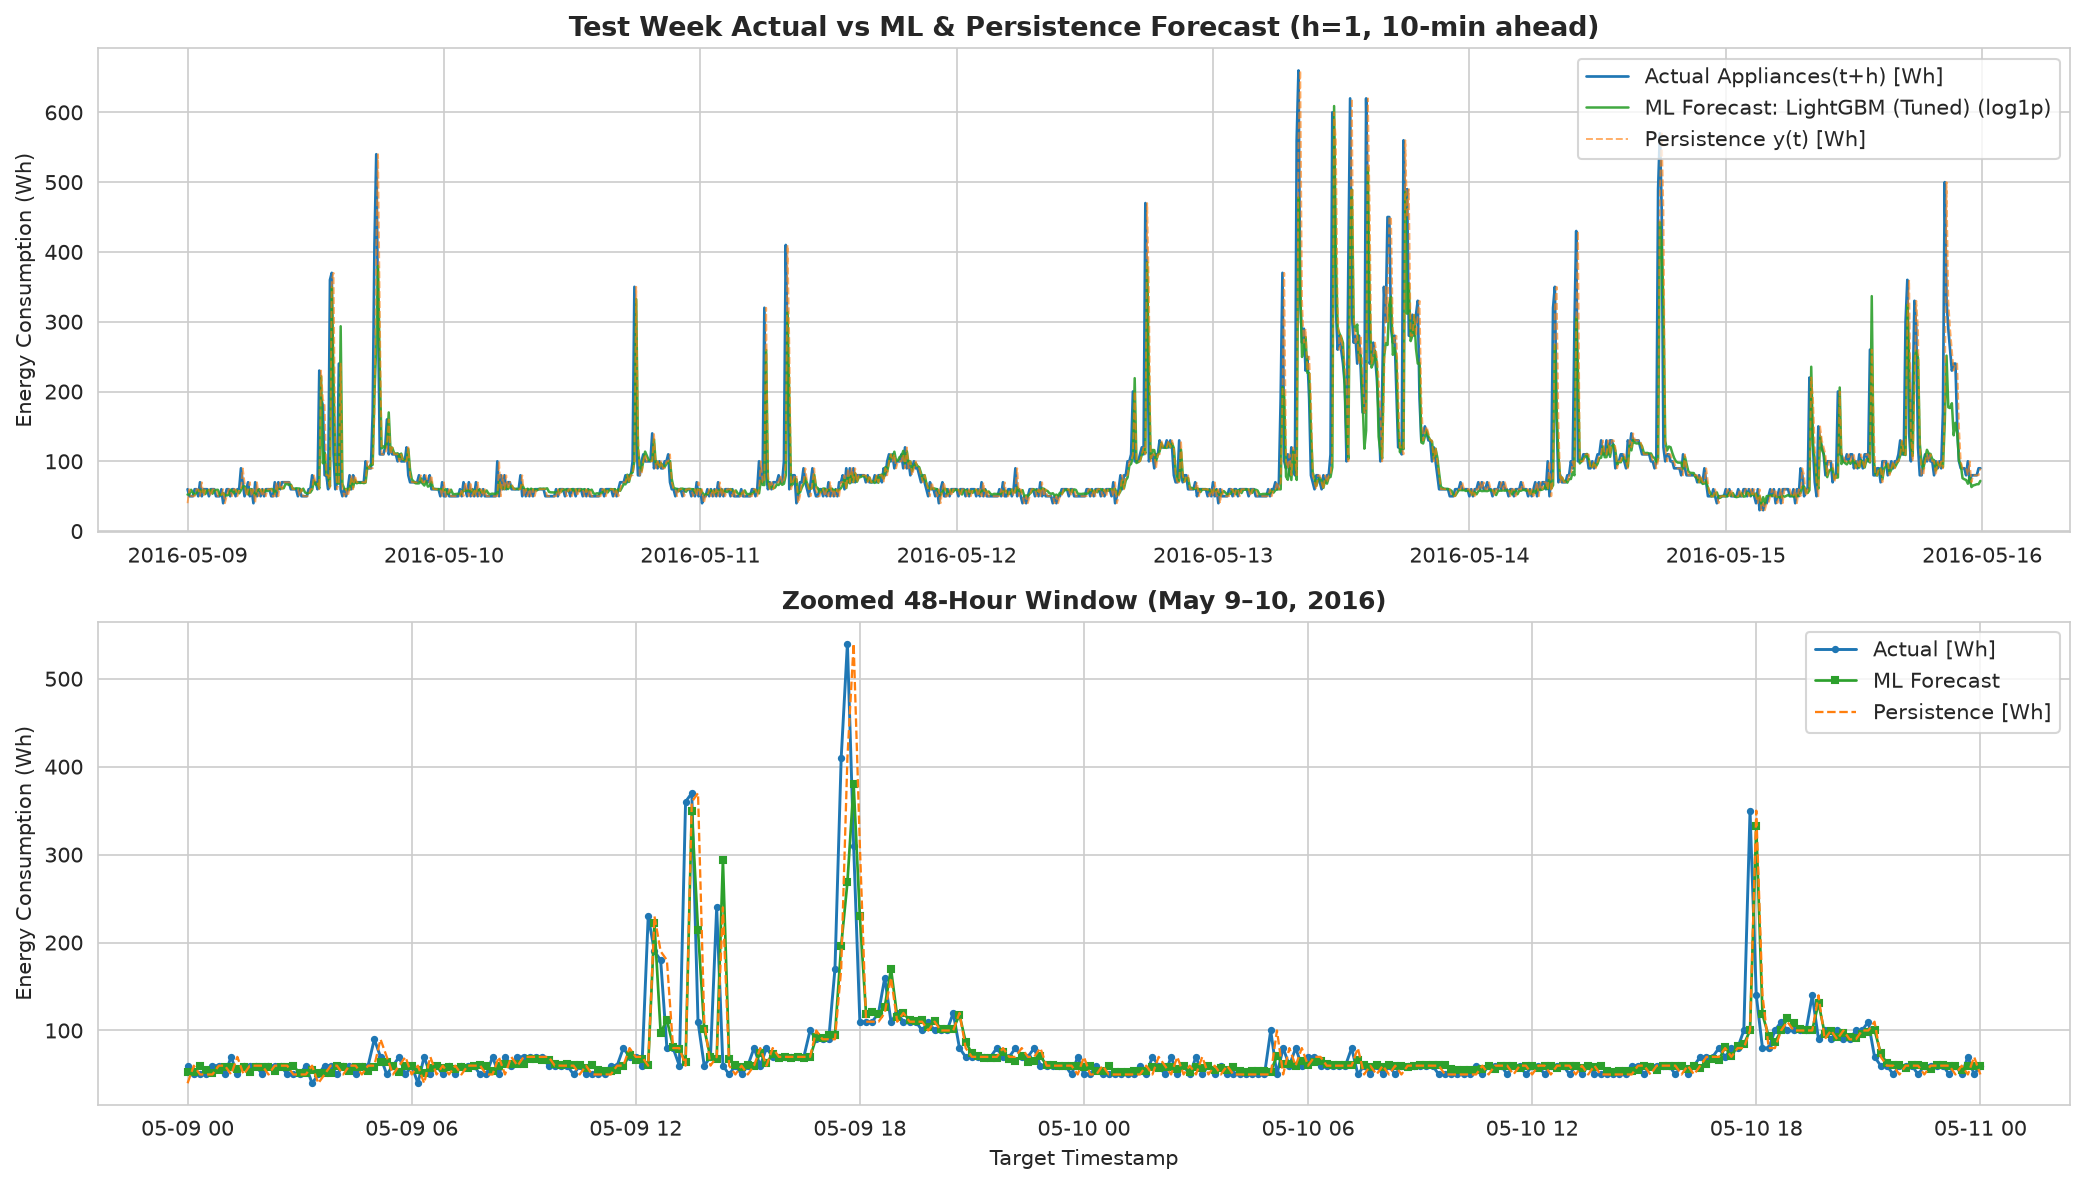

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/07_actual_vs_pred_week_h1.png


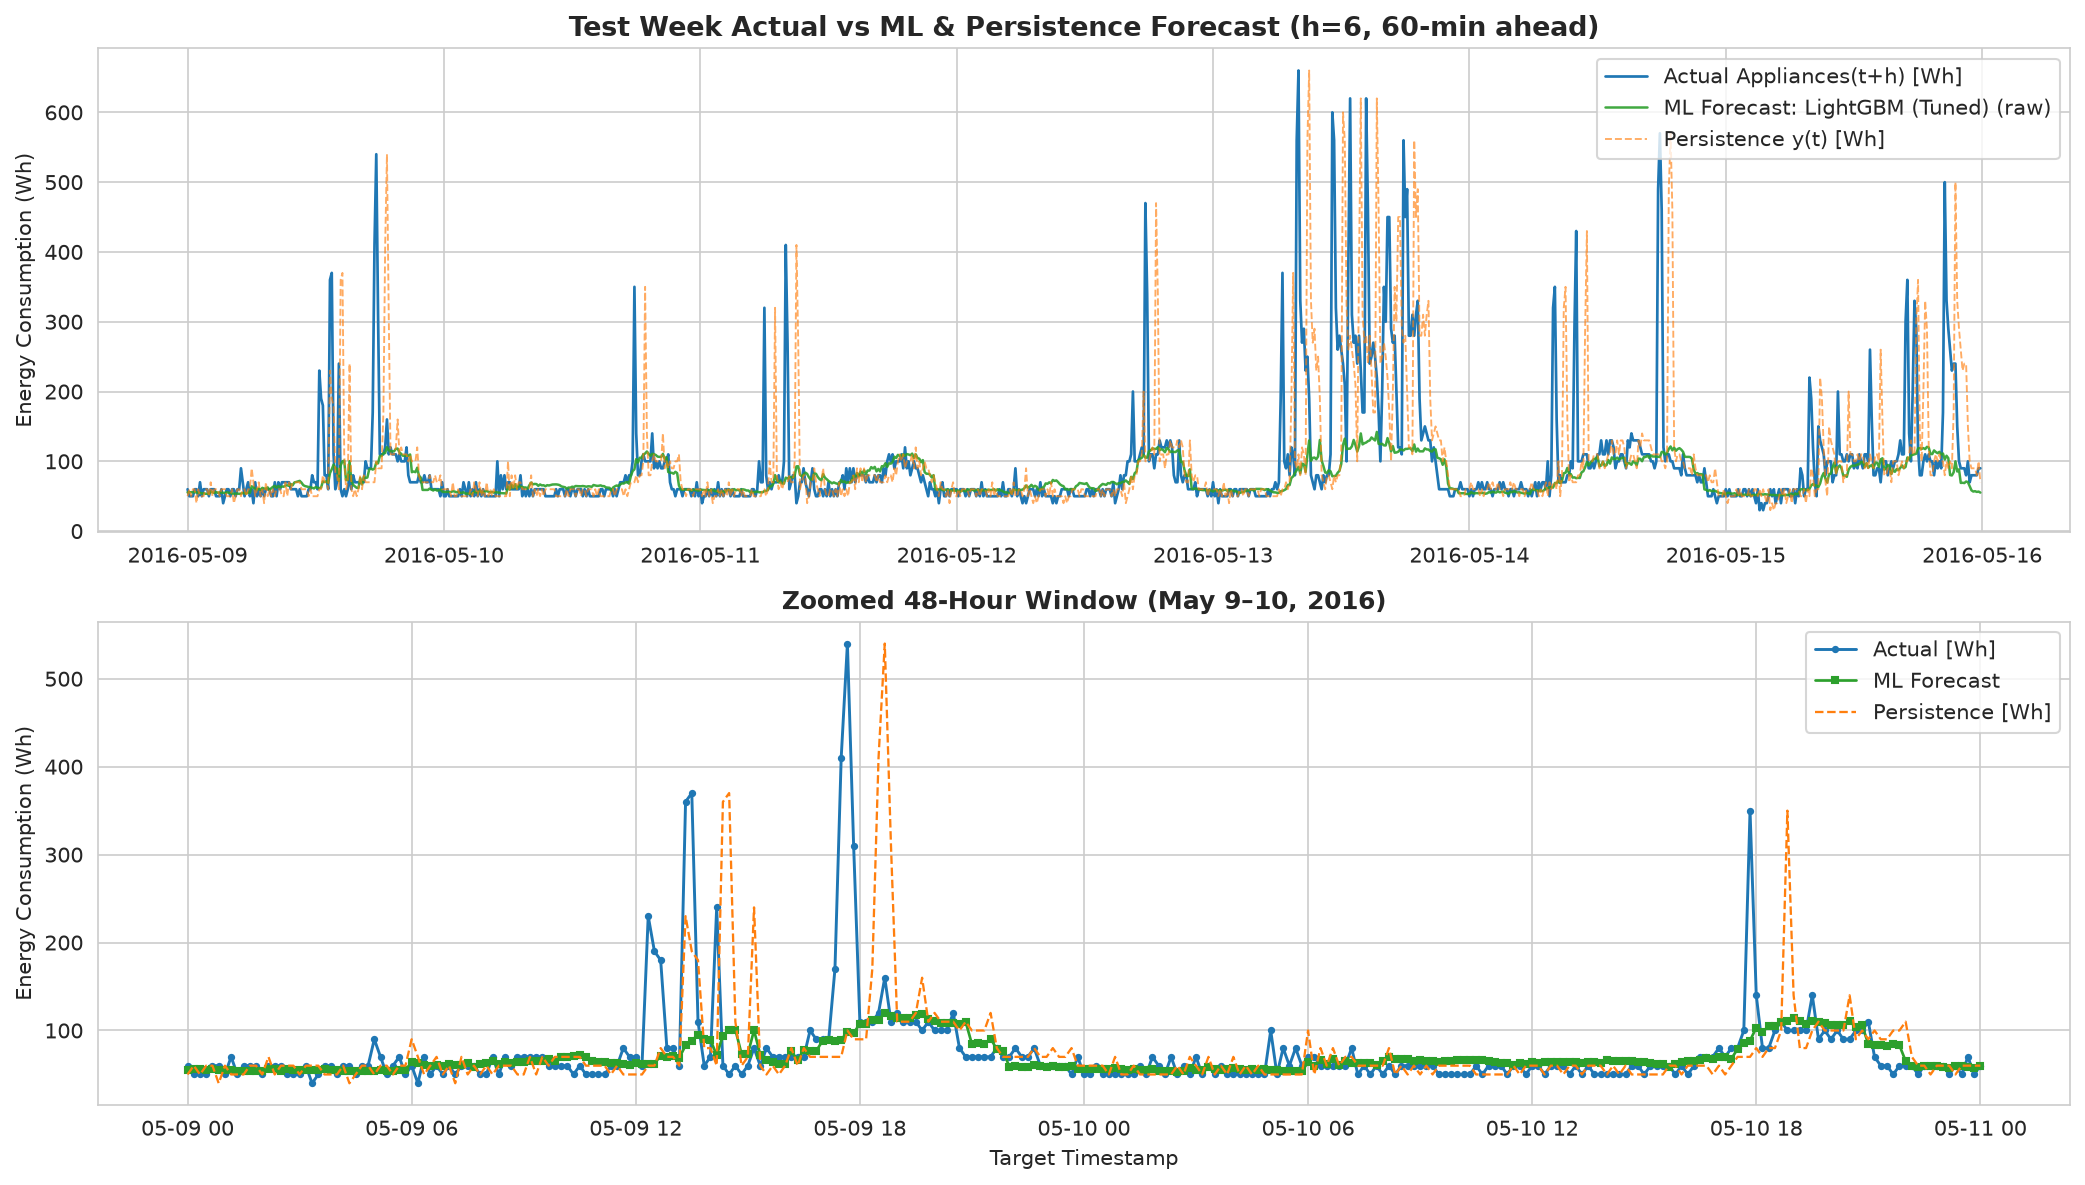

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/08_actual_vs_pred_week_h6.png


In [8]:
# ---------------------------------------------------------------------
# Plots 1 & 2: Actual vs Predicted (Typical Test Week: May 9-15, 2016)
# ---------------------------------------------------------------------
week_start = pd.Timestamp("2016-05-09 00:00:00")
week_end = pd.Timestamp("2016-05-15 23:50:00")

for h, fig_name in [(1, "07_actual_vs_pred_week_h1.png"), (6, "08_actual_vs_pred_week_h6.png")]:
    meta = datasets[h]["meta_test"].copy()
    meta["ml_pred"] = best_production[h]["test_pred"]
    mask = (meta["target_date"] >= week_start) & (meta["target_date"] <= week_end)
    wk = meta[mask]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
    model_label = f"{best_production[h]['row']['Model']} ({best_production[h]['row']['Target_Transform']})"

    axes[0].plot(wk["target_date"], wk["target"], color="#1f77b4", linewidth=1.3, label="Actual Appliances(t+h) [Wh]")
    axes[0].plot(wk["target_date"], wk["ml_pred"], color="#2ca02c", linewidth=1.2, alpha=0.9, label=f"ML Forecast: {model_label}")
    axes[0].plot(wk["target_date"], wk["Appliances_t"], color="#ff7f0e", linewidth=0.9, linestyle="--", alpha=0.65, label="Persistence y(t) [Wh]")
    axes[0].set_title(f"Test Week Actual vs ML & Persistence Forecast (h={h}, {h*10}-min ahead)", fontsize=13, fontweight="bold")
    axes[0].set_ylabel("Energy Consumption (Wh)")
    axes[0].legend(loc="upper right")

    zoom = wk[(wk["target_date"] >= "2016-05-09") & (wk["target_date"] <= "2016-05-11 00:00:00")]
    axes[1].plot(zoom["target_date"], zoom["target"], color="#1f77b4", marker="o", markersize=2.5, linewidth=1.4, label="Actual [Wh]")
    axes[1].plot(zoom["target_date"], zoom["ml_pred"], color="#2ca02c", marker="s", markersize=2.5, linewidth=1.3, label=f"ML Forecast")
    axes[1].plot(zoom["target_date"], zoom["Appliances_t"], color="#ff7f0e", linestyle="--", linewidth=1.1, label="Persistence [Wh]")
    axes[1].set_title("Zoomed 48-Hour Window (May 9–10, 2016)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Target Timestamp")
    axes[1].set_ylabel("Energy Consumption (Wh)")
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    out_p = FIG_DIR / fig_name
    plt.savefig(out_p, dpi=150)
    plt.show()
    print(f"Saved: {out_p}")


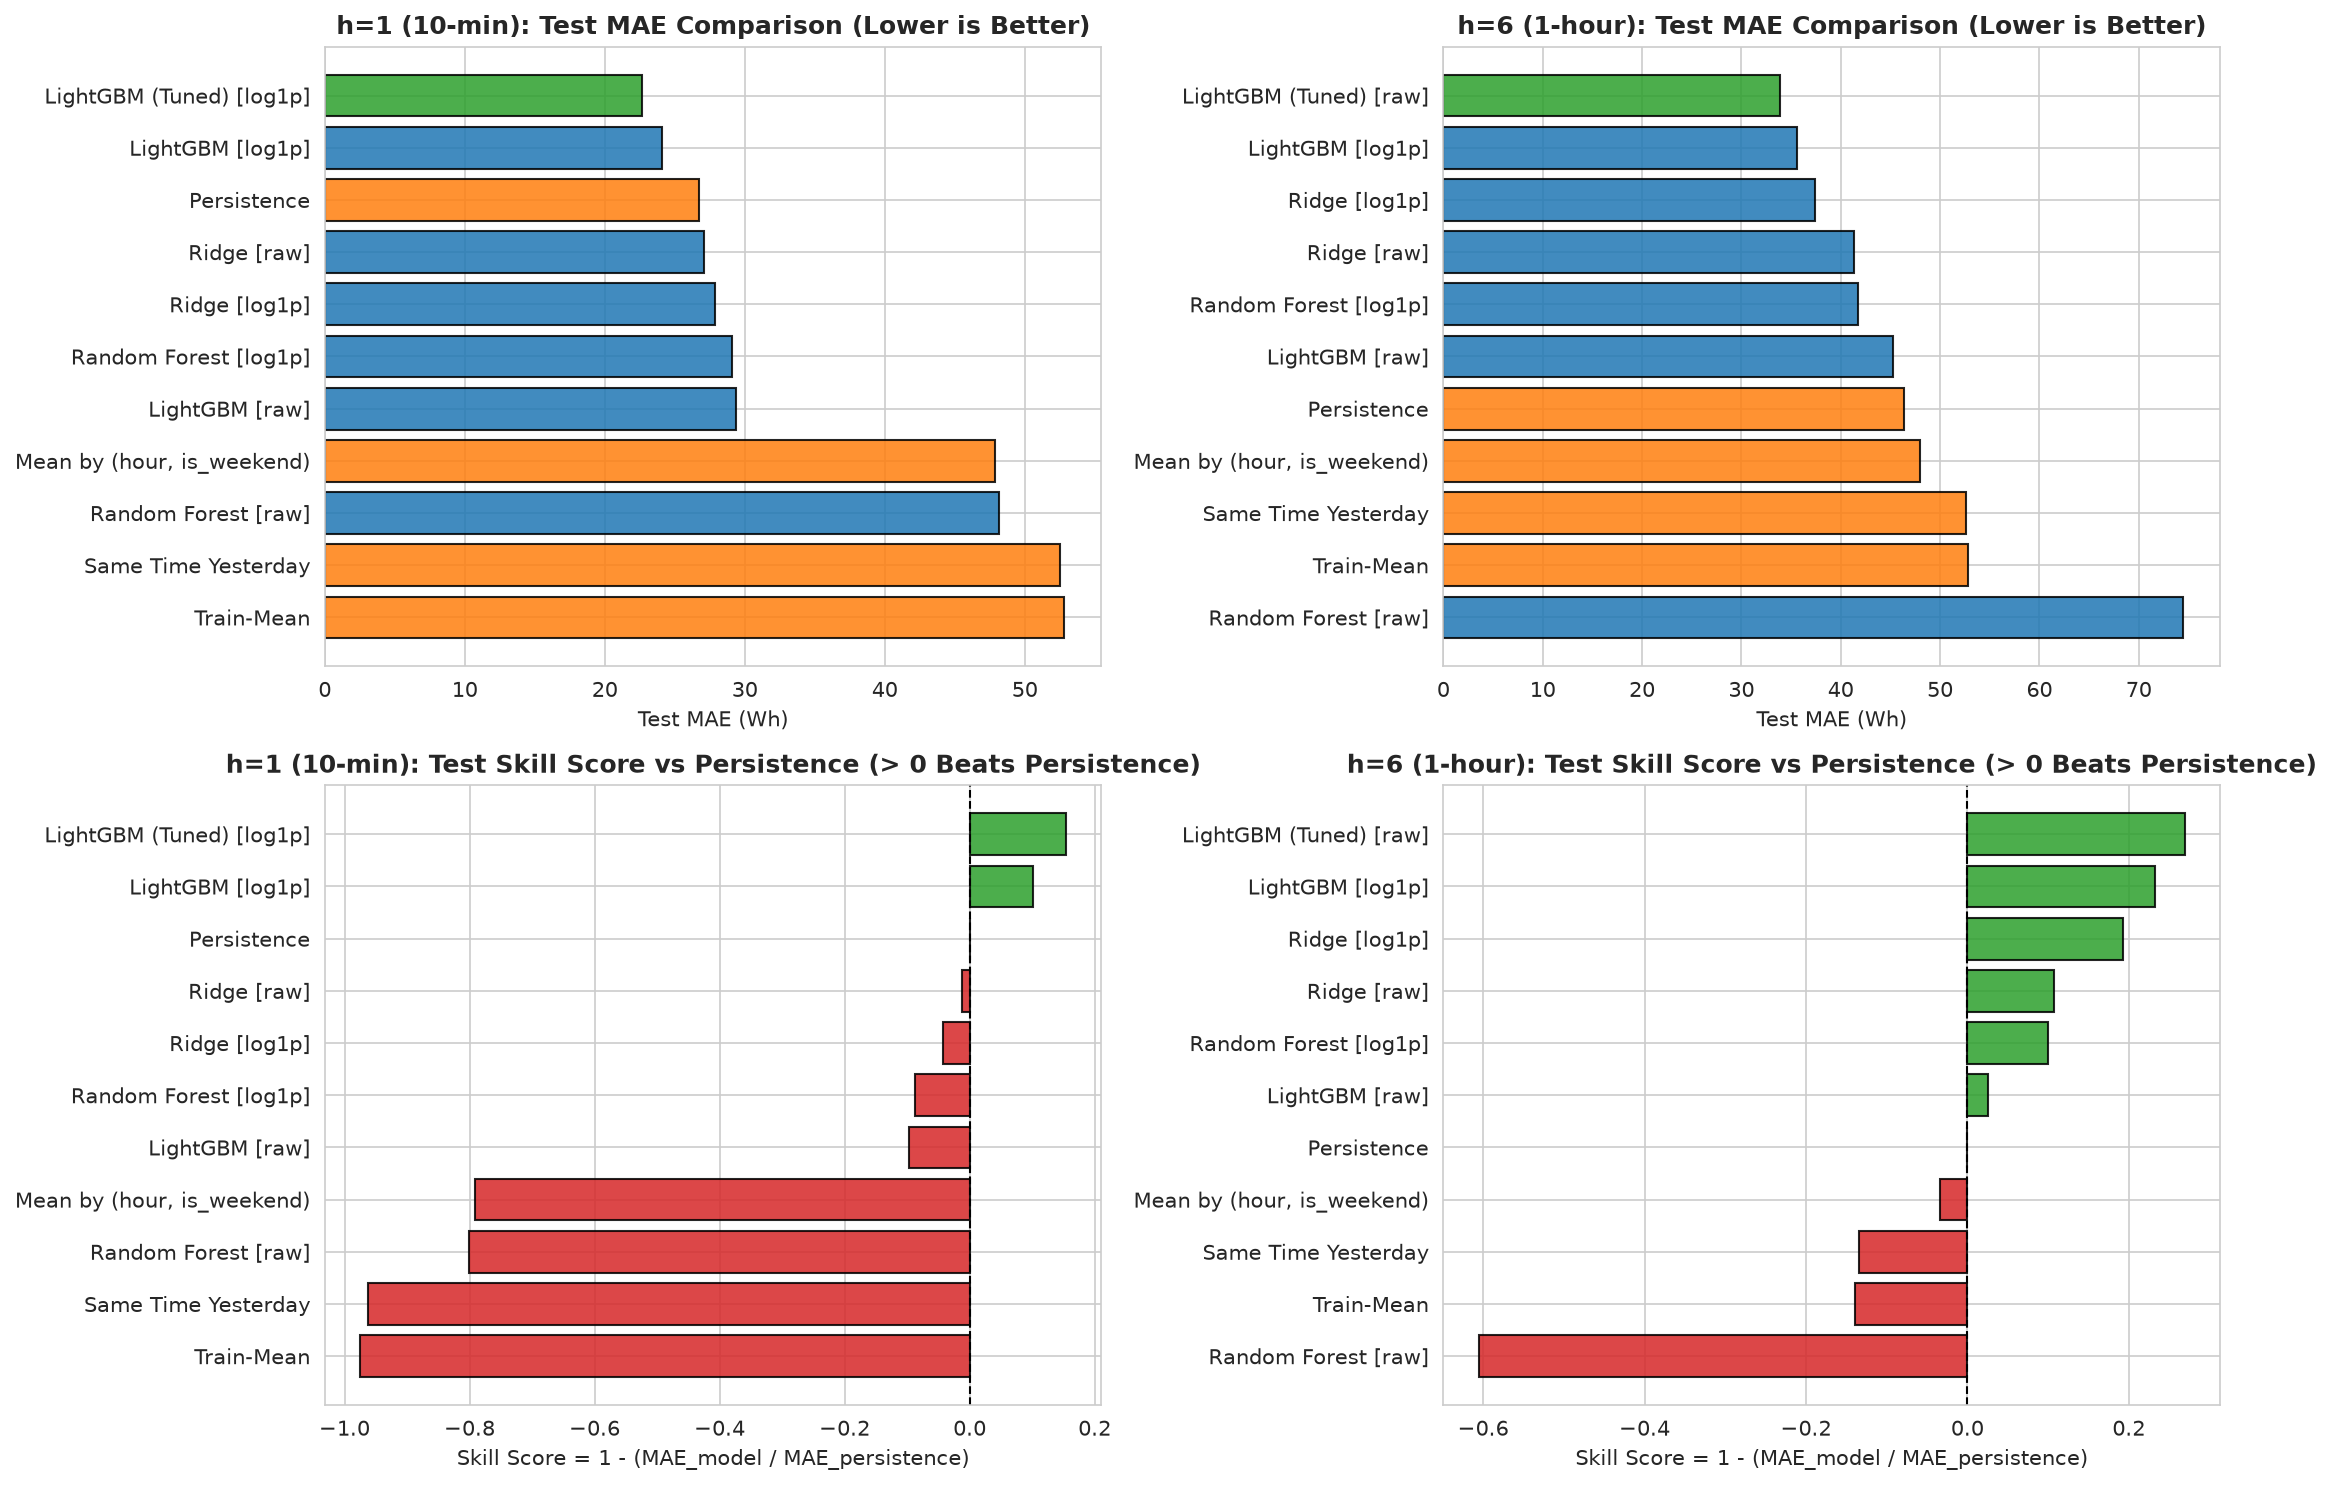

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/09_ml_vs_persistence_comparison.png


In [9]:
# ---------------------------------------------------------------------
# Plot 3: ML Models vs Baselines (Test MAE & Skill Score)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col_idx, h_label in enumerate(("h=1 (10-min)", "h=6 (1-hour)")):
    sub = unified_results_df[unified_results_df["Horizon"] == h_label].copy()
    sub["Label"] = np.where(
        sub["Target_Transform"] == "none",
        sub["Model"],
        sub["Model"] + " [" + sub["Target_Transform"] + "]",
    )
    sub = sub.sort_values("Test_MAE", ascending=True)

    colors = ["#ff7f0e" if c == "Baseline" else ("#2ca02c" if "Tuned" in c else "#1f77b4") for c in sub["Category"]]
    axes[0, col_idx].barh(sub["Label"], sub["Test_MAE"], color=colors, edgecolor="black", alpha=0.85)
    axes[0, col_idx].set_title(f"{h_label}: Test MAE Comparison (Lower is Better)", fontweight="bold")
    axes[0, col_idx].set_xlabel("Test MAE (Wh)")
    axes[0, col_idx].invert_yaxis()

    skill_colors = ["#2ca02c" if s > 0 else "#d62728" for s in sub["Test_Skill_vs_Persist"]]
    axes[1, col_idx].barh(sub["Label"], sub["Test_Skill_vs_Persist"], color=skill_colors, edgecolor="black", alpha=0.85)
    axes[1, col_idx].axvline(0.0, color="black", linestyle="--", linewidth=1.0)
    axes[1, col_idx].set_title(f"{h_label}: Test Skill Score vs Persistence (> 0 Beats Persistence)", fontweight="bold")
    axes[1, col_idx].set_xlabel("Skill Score = 1 - (MAE_model / MAE_persistence)")
    axes[1, col_idx].invert_yaxis()

plt.tight_layout()
p3 = FIG_DIR / "09_ml_vs_persistence_comparison.png"
plt.savefig(p3, dpi=150)
plt.show()
print(f"Saved: {p3}")


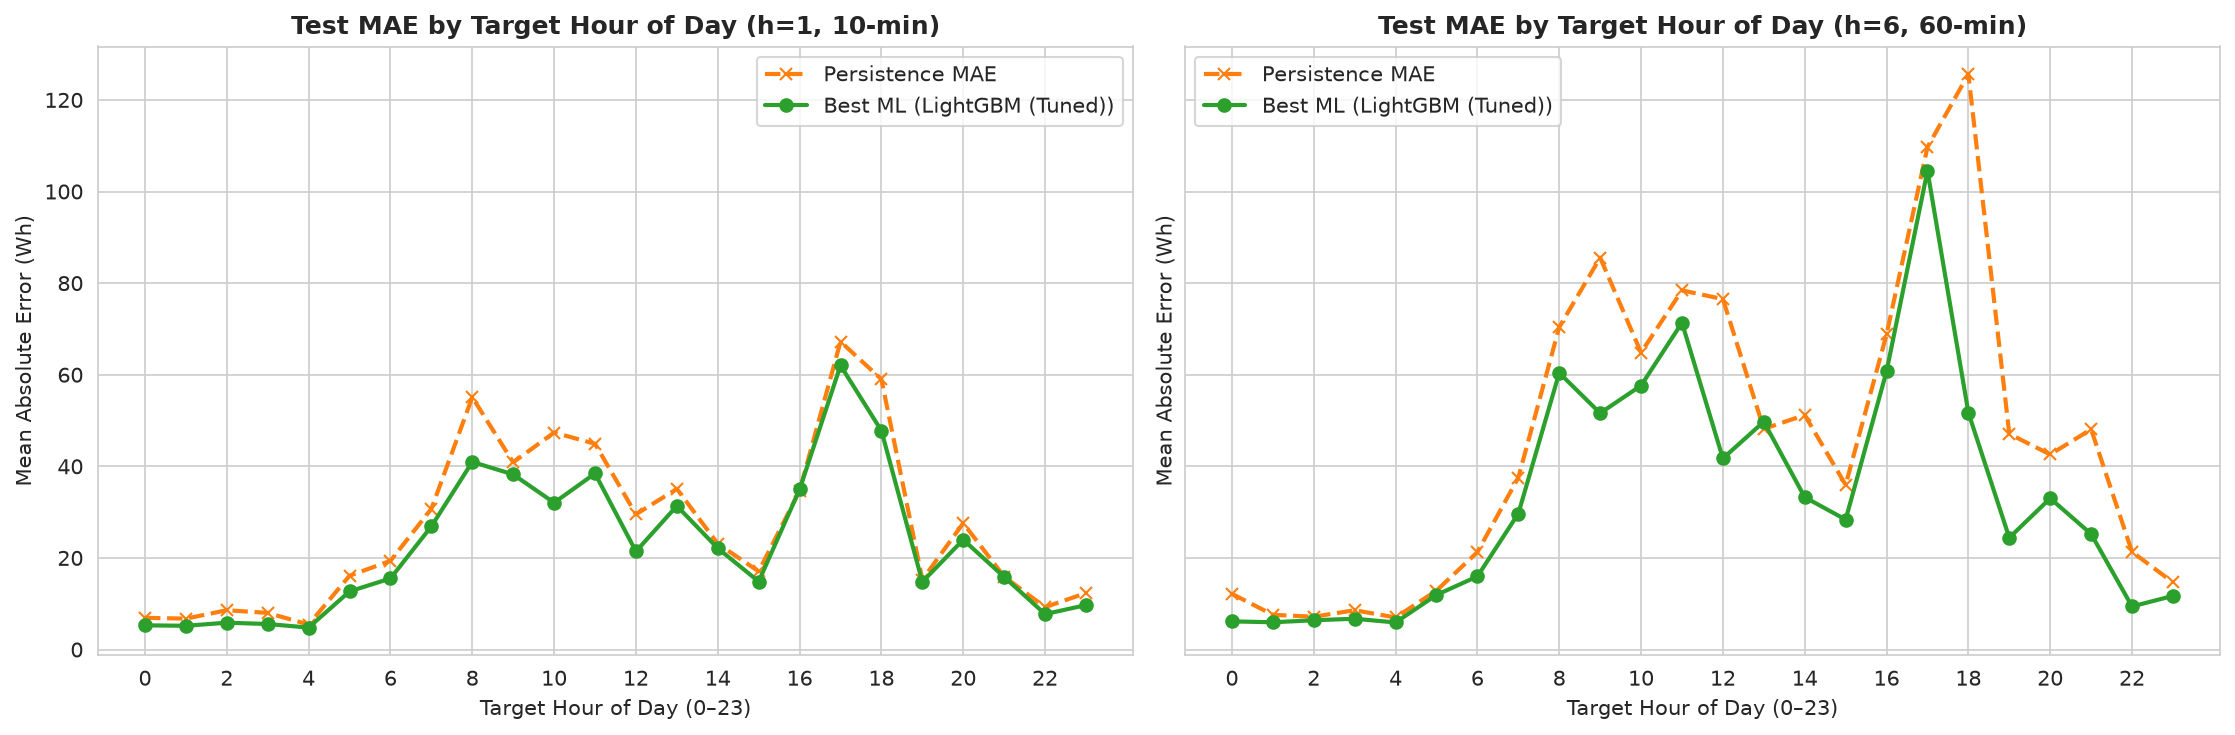

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/10_error_by_hour_of_day.png


In [10]:
# ---------------------------------------------------------------------
# Plot 4: Absolute Prediction Error by Hour of Day (Test Set)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for idx, h in enumerate((1, 6)):
    meta = datasets[h]["meta_test"].copy()
    meta["target_hour"] = pd.to_datetime(meta["target_date"]).dt.hour
    meta["err_ml"] = np.abs(meta["target"] - best_production[h]["test_pred"])
    meta["err_persist"] = np.abs(meta["target"] - meta["Appliances_t"])

    hourly_err = meta.groupby("target_hour")[["err_ml", "err_persist"]].mean()
    axes[idx].plot(hourly_err.index, hourly_err["err_persist"], marker="x", linestyle="--", color="#ff7f0e", linewidth=2, label="Persistence MAE")
    axes[idx].plot(hourly_err.index, hourly_err["err_ml"], marker="o", color="#2ca02c", linewidth=2, label=f"Best ML ({best_production[h]['row']['Model']})")
    axes[idx].set_title(f"Test MAE by Target Hour of Day (h={h}, {h*10}-min)", fontweight="bold")
    axes[idx].set_xlabel("Target Hour of Day (0–23)")
    axes[idx].set_ylabel("Mean Absolute Error (Wh)")
    axes[idx].set_xticks(range(0, 24, 2))
    axes[idx].legend()

plt.tight_layout()
p4 = FIG_DIR / "10_error_by_hour_of_day.png"
plt.savefig(p4, dpi=150)
plt.show()
print(f"Saved: {p4}")


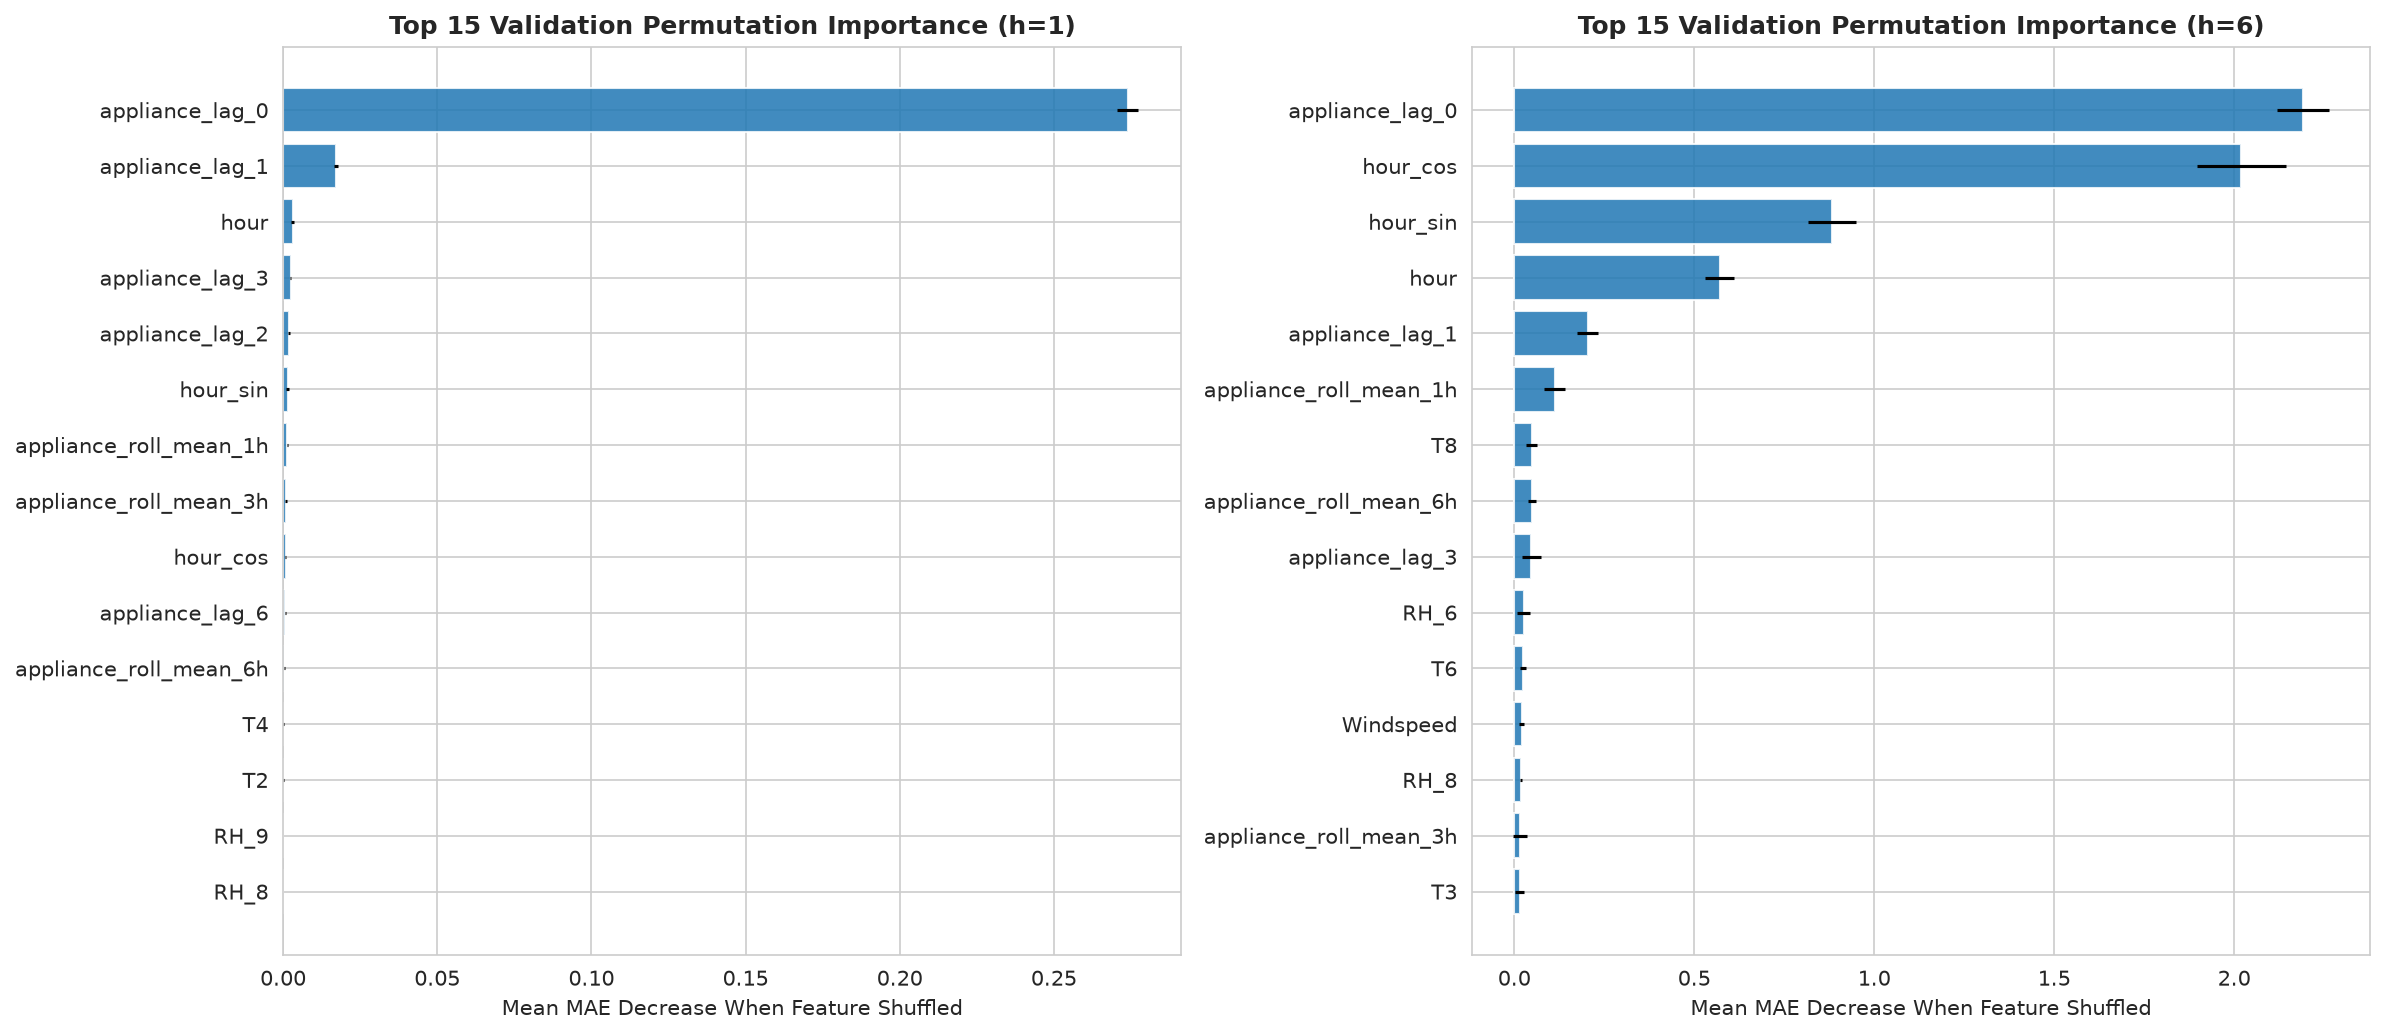

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/11_permutation_importance.png


In [11]:
# ---------------------------------------------------------------------
# Plot 5: Permutation Feature Importance (Validation Set, Top 15)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
perm_results = {}

for idx, h in enumerate((1, 6)):
    ds = datasets[h]
    bundle = best_production[h]
    t_name = bundle["row"]["Target_Transform"]
    y_val_target = np.log1p(ds["y_val"]) if t_name == "log1p" else ds["y_val"]

    r = permutation_importance(
        bundle["model"],
        ds["X_val"],
        y_val_target,
        n_repeats=10,
        random_state=RANDOM_STATE,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    imp_df = pd.DataFrame({
        "feature": ds["feature_cols"],
        "importance_mean": r.importances_mean,
        "importance_std": r.importances_std,
    }).sort_values("importance_mean", ascending=False).reset_index(drop=True)
    perm_results[h] = imp_df

    top15 = imp_df.head(15).iloc[::-1]
    axes[idx].barh(top15["feature"], top15["importance_mean"], xerr=top15["importance_std"], color="#1f77b4", alpha=0.85)
    axes[idx].set_title(f"Top 15 Validation Permutation Importance (h={h})", fontweight="bold")
    axes[idx].set_xlabel("Mean MAE Decrease When Feature Shuffled")

plt.tight_layout()
p5 = FIG_DIR / "11_permutation_importance.png"
plt.savefig(p5, dpi=150)
plt.show()
print(f"Saved: {p5}")


## Section 11: Random-Variable (`rv1`, `rv2`) Negative-Control Diagnostic

We train a separate diagnostic model (excluded from the production leaderboard) that adds `rv1` and `rv2` to the feature matrix and evaluates validation permutation importance.

**Why Individual Permutation Alone Is Insufficient:** In UCI Dataset 374, `rv1` and `rv2` are exact bit-for-bit duplicate columns (`rv1 == rv2`). Permuting `rv1` alone while leaving `rv2` unpermuted (or vice versa) still leaves the identical information available in the unpermuted copy, which can understate any spurious reliance on that noise channel. Therefore, alongside individual permutation importance, we perform a **joint permutation diagnostic** that applies the exact same row permutation to both `rv1` and `rv2` simultaneously.

**Methodological Caveat:** Demonstrating that uniform random noise variables receive near-zero individual and joint importance serves only as a **negative-control sanity check**; it does **not** prove the absence of temporal data leakage.


Negative-control duplicate check: (rv1 == rv2).all() = True | max(|rv1 - rv2|) = 0.0


/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


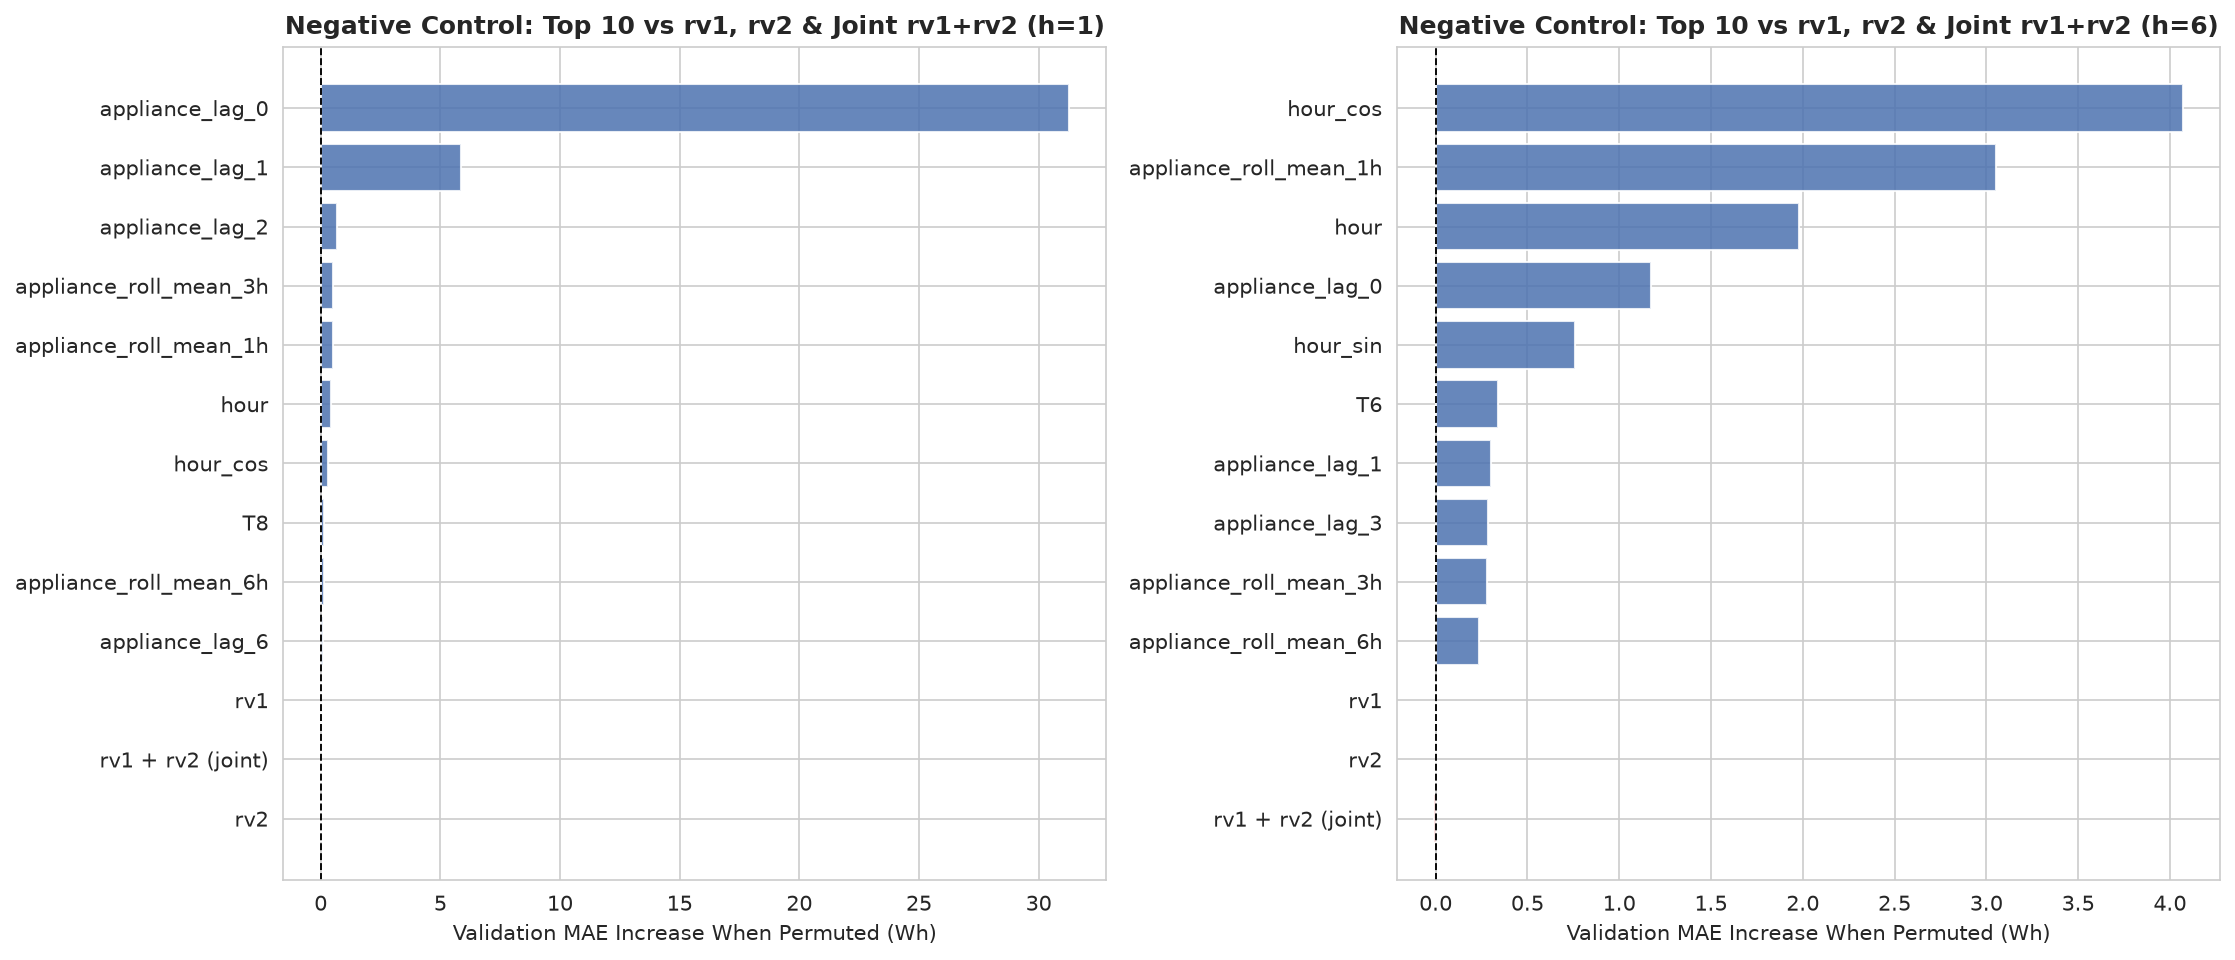

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/13_negative_control_rv1_rv2.png


,Horizon,Control,Rank_Individual,Val_MAE_Increase_Wh,Std_Wh,Top_Feature,Top_Feature_Wh
0,h=1,rv1 (individual),19 / 45,0.013319,0.015336,appliance_lag_0,31.2616
1,h=1,rv2 (individual),34 / 45,-0.006998,0.004077,appliance_lag_0,31.2616
2,h=1,rv1 + rv2 (joint),33 / 45 (equiv.),-0.002213,0.013137,appliance_lag_0,31.2616
3,h=6,rv1 (individual),31 / 45,0.000923,0.006578,hour_cos,4.0690
4,h=6,rv2 (individual),33 / 45,0.000000,0.000000,hour_cos,4.0690
5,h=6,rv1 + rv2 (joint),35 / 45 (equiv.),-0.007502,0.004654,hour_cos,4.0690


In [12]:
rv_exact_equal = bool((df["rv1"] == df["rv2"]).all())
rv_max_diff = float((df["rv1"] - df["rv2"]).abs().max())
print(f"Negative-control duplicate check: (rv1 == rv2).all() = {rv_exact_equal} | max(|rv1 - rv2|) = {rv_max_diff}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
neg_control_summary = []

for idx, h in enumerate((1, 6)):
    ds_nc = prepare_forecast_datasets(df, horizon=h, include_random_controls=True)
    diag_model, _ = fit_and_predict_model(
        "LightGBM", "raw", ds_nc["X_train"], ds_nc["y_train"], ds_nc["X_val"], ds_nc["y_val"]
    )
    X_val_nc = ds_nc["X_val"]
    y_val_nc = ds_nc["y_val"]

    # Individual permutation importance (10 repeats)
    r_nc = permutation_importance(
        diag_model,
        X_val_nc,
        y_val_nc,
        n_repeats=10,
        random_state=RANDOM_STATE,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    nc_df = pd.DataFrame({
        "feature": ds_nc["feature_cols"],
        "importance_mean": r_nc.importances_mean,
        "importance_std": r_nc.importances_std,
    }).sort_values("importance_mean", ascending=False).reset_index(drop=True)
    nc_df["rank"] = nc_df.index + 1

    # Joint permutation importance: apply identical row shuffle to both rv1 and rv2 simultaneously
    base_val_mae = float(mean_absolute_error(y_val_nc, diag_model.predict(X_val_nc)))
    rng = np.random.default_rng(RANDOM_STATE)
    joint_deltas = []
    for _ in range(10):
        perm_idx = rng.permutation(len(X_val_nc))
        X_perm = X_val_nc.copy()
        X_perm["rv1"] = X_val_nc["rv1"].iloc[perm_idx].to_numpy()
        X_perm["rv2"] = X_val_nc["rv2"].iloc[perm_idx].to_numpy()
        perm_mae = float(mean_absolute_error(y_val_nc, diag_model.predict(X_perm)))
        joint_deltas.append(perm_mae - base_val_mae)
    joint_mean = float(np.mean(joint_deltas))
    joint_std = float(np.std(joint_deltas))

    for rv_col in ("rv1", "rv2"):
        row_rv = nc_df[nc_df["feature"] == rv_col].iloc[0]
        neg_control_summary.append({
            "Horizon": f"h={h}",
            "Control": f"{rv_col} (individual)",
            "Rank_Individual": f"{int(row_rv['rank'])} / {len(nc_df)}",
            "Val_MAE_Increase_Wh": round(float(row_rv["importance_mean"]), 6),
            "Std_Wh": round(float(row_rv["importance_std"]), 6),
            "Top_Feature": nc_df.iloc[0]["feature"],
            "Top_Feature_Wh": round(float(nc_df.iloc[0]["importance_mean"]), 4),
        })

    neg_control_summary.append({
        "Horizon": f"h={h}",
        "Control": "rv1 + rv2 (joint)",
        "Rank_Individual": f"{int((nc_df['importance_mean'] > joint_mean).sum()) + 1} / {len(nc_df)} (equiv.)",
        "Val_MAE_Increase_Wh": round(joint_mean, 6),
        "Std_Wh": round(joint_std, 6),
        "Top_Feature": nc_df.iloc[0]["feature"],
        "Top_Feature_Wh": round(float(nc_df.iloc[0]["importance_mean"]), 4),
    })

    # Plot Top 10 features + rv1 (indiv), rv2 (indiv), and rv1+rv2 (joint)
    joint_row = pd.DataFrame([{"feature": "rv1 + rv2 (joint)", "importance_mean": joint_mean}])
    plot_df = pd.concat(
        [nc_df.head(10)[["feature", "importance_mean"]], nc_df[nc_df["feature"].isin(["rv1", "rv2"])][["feature", "importance_mean"]], joint_row]
    ).drop_duplicates("feature")
    plot_df = plot_df.sort_values("importance_mean", ascending=True)
    bar_colors = ["#d62728" if "rv" in f else "#4c72b0" for f in plot_df["feature"]]
    axes[idx].barh(plot_df["feature"], plot_df["importance_mean"], color=bar_colors, alpha=0.85)
    axes[idx].axvline(0.0, color="black", linewidth=0.9, linestyle="--")
    axes[idx].set_title(f"Negative Control: Top 10 vs rv1, rv2 & Joint rv1+rv2 (h={h})", fontweight="bold")
    axes[idx].set_xlabel("Validation MAE Increase When Permuted (Wh)")

plt.tight_layout()
p_nc = FIG_DIR / "13_negative_control_rv1_rv2.png"
plt.savefig(p_nc, dpi=150)
plt.show()
print(f"Saved: {p_nc}")
display(pd.DataFrame(neg_control_summary))


## Section 12: High-Consumption Spike Analysis (`>= 300 Wh` Threshold)

Following Review 1, we evaluate spike event detection on the test set using `300 Wh` as the high-consumption threshold (95th+ percentile tail). Because point-regression models optimize conditional expectation (or median under L1), rare sharp spikes are inherently difficult to anticipate—we report Precision, Recall, F1, True Positives, Missed Spikes (False Negatives), and False Alarms (False Positives) alongside Persistence.


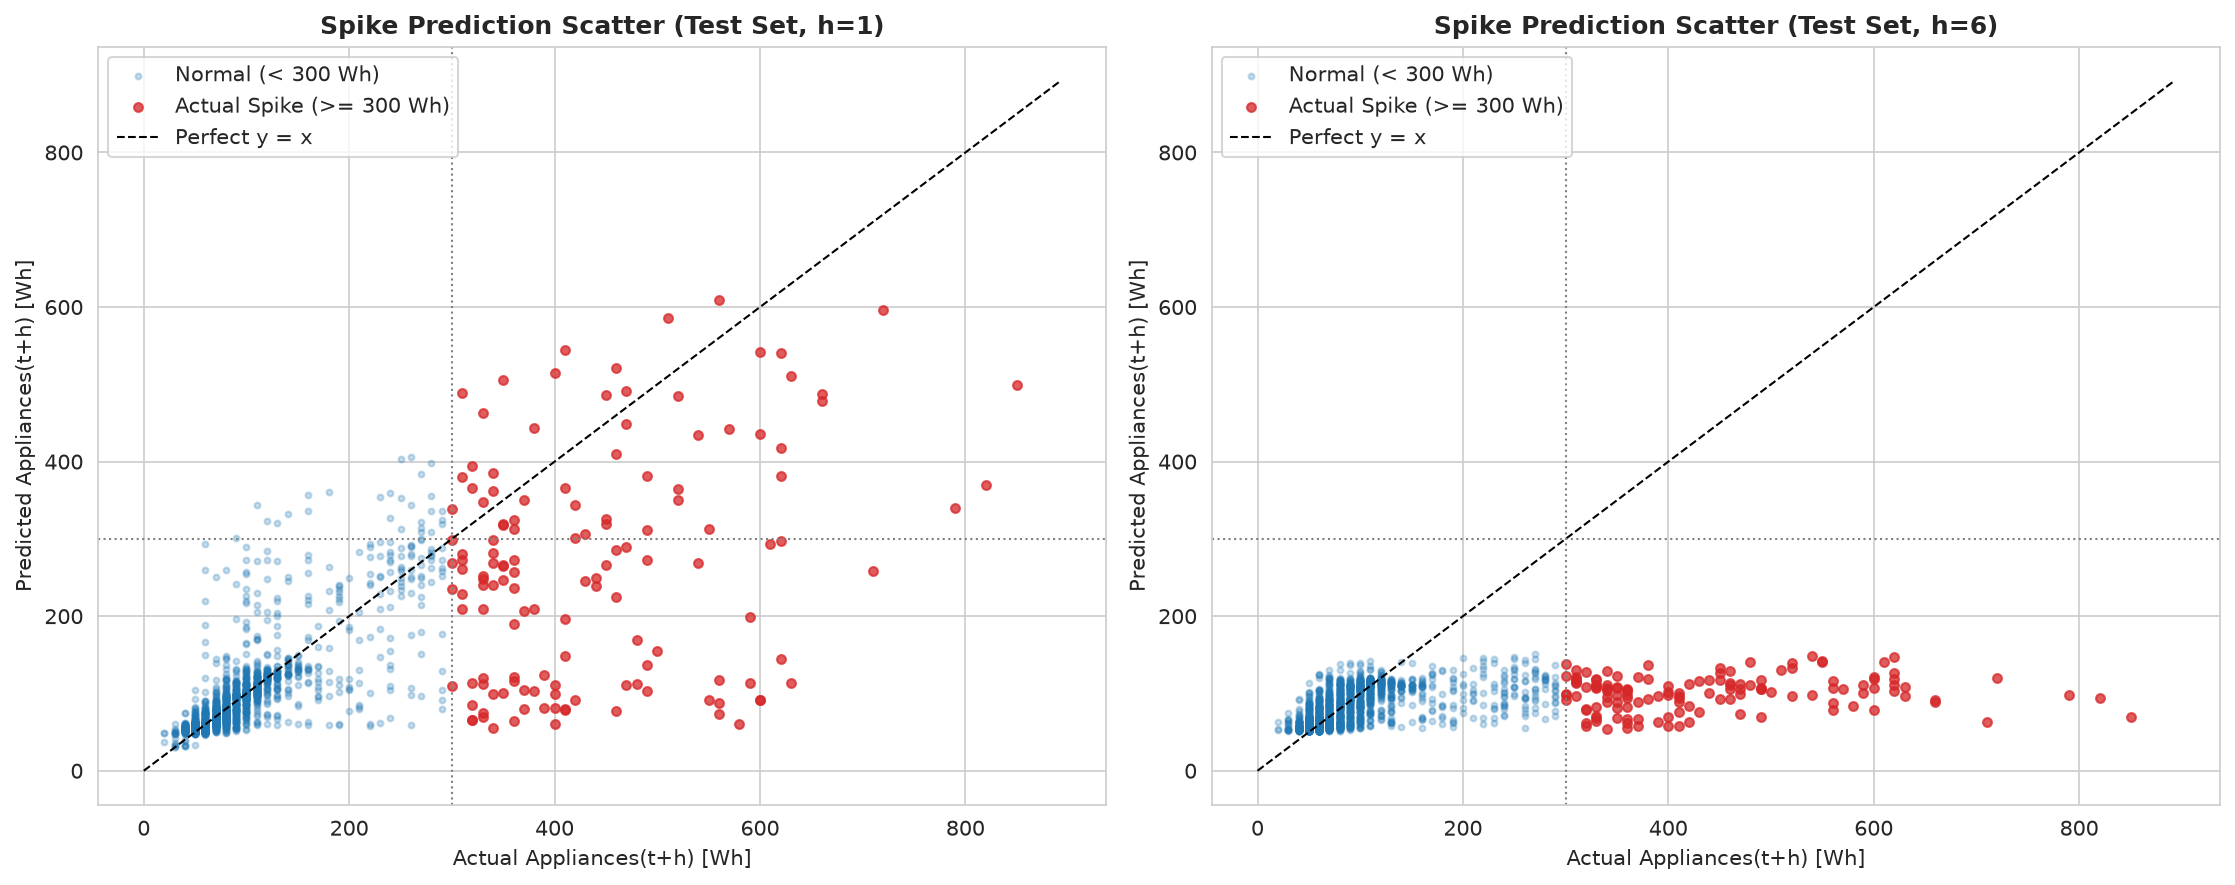

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/12_spike_prediction_analysis.png


,Horizon,Model,Threshold_Wh,Actual_Spikes,Predicted_Spikes,True_Positives,Missed_Spikes_FN,False_Alarms_FP,Precision,Recall,F1
0,h=1,Persistence,300.0,135,134,65,70,69,0.4851,0.4815,0.4833
1,h=1,Best ML (LightGBM (Tuned)),300.0,135,78,51,84,27,0.6538,0.3778,0.4789
2,h=6,Persistence,300.0,135,133,17,118,116,0.1278,0.1259,0.1269
3,h=6,Best ML (LightGBM (Tuned)),300.0,135,0,0,135,0,0.0000,0.0000,0.0000


In [13]:
SPIKE_THRESHOLD = 300.0
spike_rows = []

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for idx, h in enumerate((1, 6)):
    meta = datasets[h]["meta_test"].copy()
    y_true = meta["target"].values
    y_ml = best_production[h]["test_pred"]
    y_pers = meta["Appliances_t"].values

    actual_spike = y_true >= SPIKE_THRESHOLD
    for label, preds in [("Persistence", y_pers), (f"Best ML ({best_production[h]['row']['Model']})", y_ml)]:
        pred_spike = preds >= SPIKE_THRESHOLD
        tp = int((actual_spike & pred_spike).sum())
        fp = int((~actual_spike & pred_spike).sum())
        fn = int((actual_spike & ~pred_spike).sum())
        spike_rows.append({
            "Horizon": f"h={h}",
            "Model": label,
            "Threshold_Wh": SPIKE_THRESHOLD,
            "Actual_Spikes": int(actual_spike.sum()),
            "Predicted_Spikes": int(pred_spike.sum()),
            "True_Positives": tp,
            "Missed_Spikes_FN": fn,
            "False_Alarms_FP": fp,
            "Precision": round(precision_score(actual_spike, pred_spike, zero_division=0), 4),
            "Recall": round(recall_score(actual_spike, pred_spike, zero_division=0), 4),
            "F1": round(f1_score(actual_spike, pred_spike, zero_division=0), 4),
        })

    axes[idx].scatter(y_true[~actual_spike], y_ml[~actual_spike], s=8, alpha=0.25, color="#1f77b4", label="Normal (< 300 Wh)")
    axes[idx].scatter(y_true[actual_spike], y_ml[actual_spike], s=18, alpha=0.75, color="#d62728", label="Actual Spike (>= 300 Wh)")
    max_lim = max(y_true.max(), y_ml.max()) * 1.05
    axes[idx].plot([0, max_lim], [0, max_lim], "k--", linewidth=1, label="Perfect y = x")
    axes[idx].axvline(SPIKE_THRESHOLD, color="gray", linestyle=":", linewidth=1)
    axes[idx].axhline(SPIKE_THRESHOLD, color="gray", linestyle=":", linewidth=1)
    axes[idx].set_title(f"Spike Prediction Scatter (Test Set, h={h})", fontweight="bold")
    axes[idx].set_xlabel("Actual Appliances(t+h) [Wh]")
    axes[idx].set_ylabel("Predicted Appliances(t+h) [Wh]")
    axes[idx].legend(loc="upper left")

plt.tight_layout()
p6 = FIG_DIR / "12_spike_prediction_analysis.png"
plt.savefig(p6, dpi=150)
plt.show()
print(f"Saved: {p6}")
display(pd.DataFrame(spike_rows))


## Section 13: Hourly-Aggregated Forecasting Experiment

Each raw row in UCI 374 represents a 10-minute energy measurement (Wh). Summing **complete 6-interval hours** (`count == 6`) produces true hourly energy totals (Wh/hour), filtering out partial boundary hours.

**Explicit Timestamp & Forecast Convention (Unified Across Train, Validation & Test):**
1. **Row Timestamp (`current_hour_start`):** Beginning of the current complete 1-hour interval `[current_hour_start, current_hour_start + 1h)` (covering six 10-minute steps, e.g., `17:00` covers `17:00–17:50`).
2. **Forecast Origin (`origin_time = current_hour_start + 1h`):** The exact instant the current complete hourly interval has finished (e.g., `18:00`), when the completed hour's energy sum (`Appliances_hour_Wh`) and hourly sensor means are fully known.
3. **Target Interval (`target_hour_start = origin_time = current_hour_start + 1h`):** The *next* complete hourly interval `[target_hour_start, target_hour_start + 1h)`, whose energy total is `Appliances_hour_Wh.shift(-1)`.
4. **Target-Hour Alignment:** Calendar features (`target_hour`, `target_hour_sin`, `target_hour_cos`, `target_is_weekend`) and the `Hourly Mean (hour, weekend)` baseline both index by `target_hour_start` consistently across training, validation, and test splits, with all targets built strictly inside each split.


Complete hourly intervals: 3,289 (2016-01-11 17:00:00 -> 2016-05-27 17:00:00)
Sample Test Hourly Timestamp Alignment:


,current_hour_start,origin_time,target_hour_start,Appliances_hour_Wh,target_hour_Wh
0,2016-05-07 04:00:00,2016-05-07 05:00:00,2016-05-07 05:00:00,330,310.0
1,2016-05-07 05:00:00,2016-05-07 06:00:00,2016-05-07 06:00:00,310,320.0
2,2016-05-07 06:00:00,2016-05-07 07:00:00,2016-05-07 07:00:00,320,890.0


Hourly Ridge validation-selected alpha = 100.0


/home/unhealthycoder/mini-project--3rd-SEM/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,Model,Val_MAE_Wh,Val_RMSE_Wh,Val_R2,Test_MAE_Wh,Test_RMSE_Wh,Test_R2
0,Hourly Persistence,223.43,415.49,0.0542,187.65,357.52,0.2914
1,"Hourly Mean (target hour, weekend)",252.66,387.30,0.1782,249.33,385.21,0.1774
2,Hourly Ridge (val-alpha),198.19,339.10,0.3701,195.70,317.03,0.4428
3,Hourly LightGBM,173.13,353.84,0.3141,166.16,332.15,0.3884


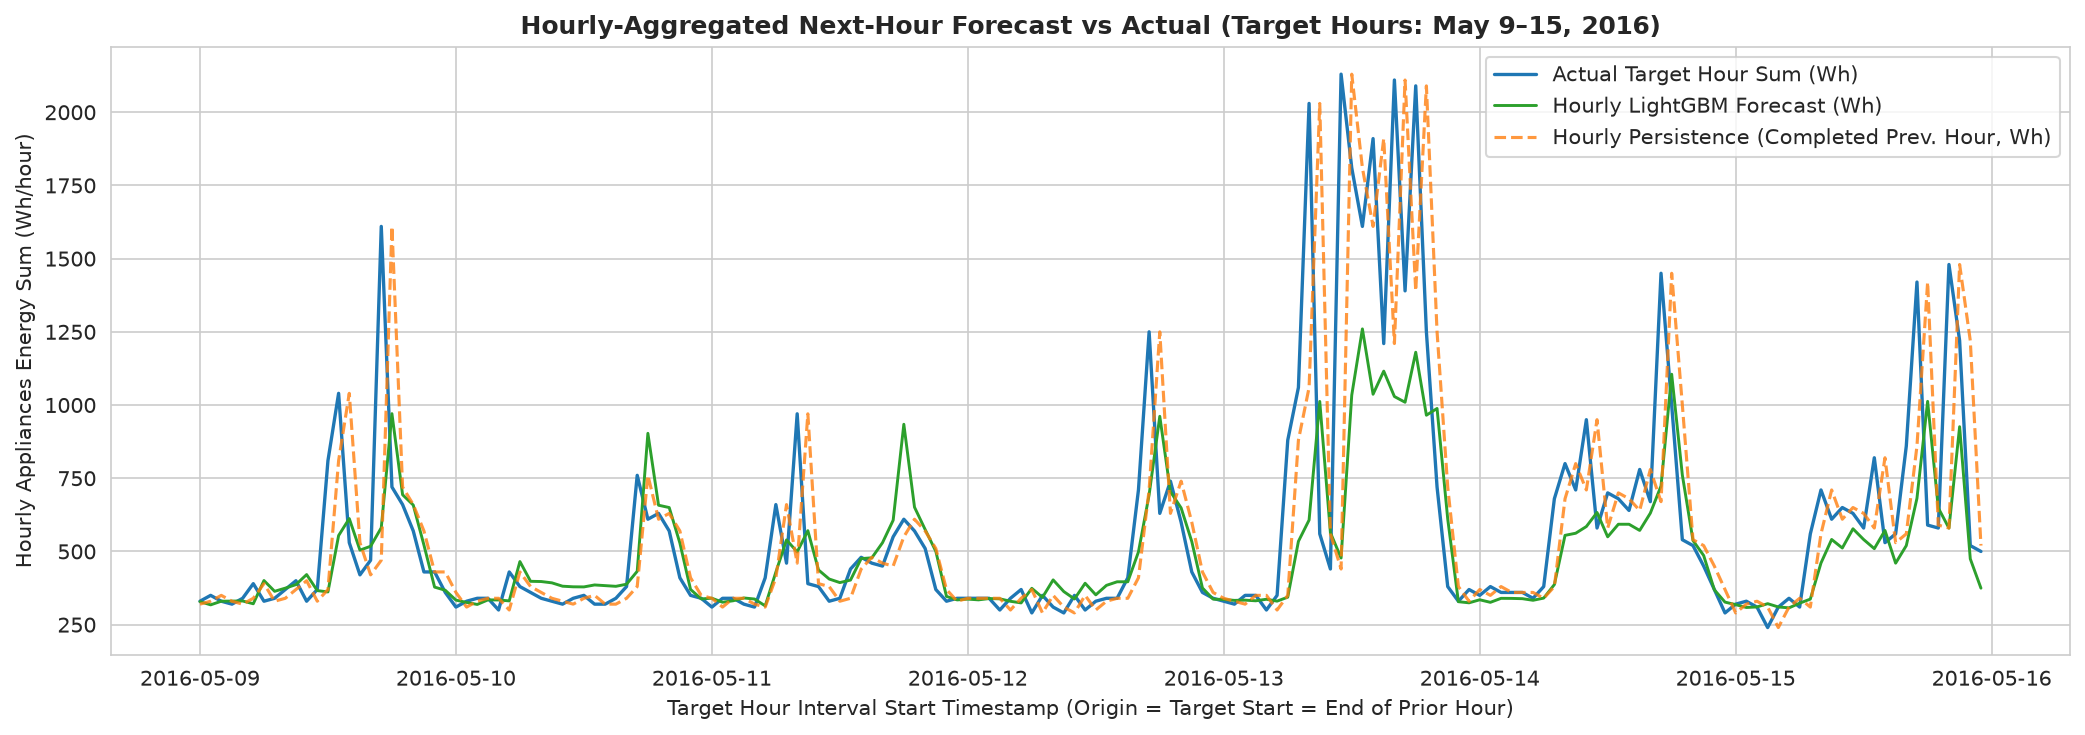

Saved: /home/unhealthycoder/mini-project--3rd-SEM/figures/14_hourly_aggregated_forecast.png


In [14]:
# Aggregate strictly complete 6-interval hours so partial edge hours never skew Wh totals
df_idx = df.set_index("date")
hourly_counts = df_idx["Appliances"].resample("1h").count()
complete_hours = hourly_counts[hourly_counts == 6].index

hourly_app_sum = df_idx["Appliances"].resample("1h").sum().loc[complete_hours]
sensor_cols = [c for c in df.columns if c not in ("date", "Appliances", "lights", "rv1", "rv2")]
hourly_sensors = df_idx[sensor_cols].resample("1h").mean().loc[complete_hours]

hourly_df = hourly_sensors.copy()
hourly_df["Appliances_hour_Wh"] = hourly_app_sum
hourly_df = hourly_df.reset_index().rename(columns={"date": "current_hour_start", "index": "current_hour_start"})
hourly_df["origin_time"] = hourly_df["current_hour_start"] + pd.Timedelta(hours=1)
hourly_df["target_hour_start"] = hourly_df["origin_time"]

# Verify strictly continuous 1-hour grid
assert (hourly_df["current_hour_start"].diff().dropna() == pd.Timedelta(hours=1)).all()
print(f"Complete hourly intervals: {len(hourly_df):,} ({hourly_df['current_hour_start'].min()} -> {hourly_df['current_hour_start'].max()})")

# Build features known at `origin_time` (completed current hour + target interval calendar)
h_feat = pd.DataFrame(index=hourly_df.index)
target_dt = hourly_df["target_hour_start"]
thr = target_dt.dt.hour.astype(float)
h_feat["target_hour"] = thr
h_feat["target_hour_sin"] = np.sin(2.0 * np.pi * thr / 24.0)
h_feat["target_hour_cos"] = np.cos(2.0 * np.pi * thr / 24.0)
h_feat["target_is_weekend"] = (target_dt.dt.day_of_week >= 5).astype(float)

# Backward-looking completed hourly consumption lags (lag_0 = completed current hour ending at origin_time)
for lag_h in (0, 1, 2, 3, 24):
    h_feat[f"hour_app_lag_{lag_h}"] = hourly_df["Appliances_hour_Wh"].shift(lag_h)

# Past rolling means over strictly prior completed hours [i-w .. i-1]
for win_h in (3, 6, 24):
    h_feat[f"hour_app_roll_{win_h}h"] = hourly_df["Appliances_hour_Wh"].shift(1).rolling(win_h).mean()

# Completed current-hour sensor averages (known once current hour finishes at origin_time)
for c in sensor_cols:
    h_feat[c] = hourly_df[c]

# Chronological 70/15/15 split
nh_total = len(hourly_df)
nh_train = int(0.70 * nh_total)
nh_val = int(0.15 * nh_total)

def slice_hourly(start, end, drop_init=False):
    sub_X = h_feat.iloc[start:end].copy()
    sub_y = hourly_df["Appliances_hour_Wh"].iloc[start:end].shift(-1)
    mask = sub_y.notna() & sub_X.notna().all(axis=1)
    if drop_init:
        mask = mask & (sub_X.index >= 24)
    meta = hourly_df.iloc[start:end].loc[mask, ["current_hour_start", "origin_time", "target_hour_start", "Appliances_hour_Wh"]].copy()
    meta["target_hour_Wh"] = sub_y.loc[mask].values
    return sub_X.loc[mask].reset_index(drop=True), sub_y.loc[mask].reset_index(drop=True), meta.reset_index(drop=True)

Xh_tr, yh_tr, mh_tr = slice_hourly(0, nh_train, drop_init=True)
Xh_va, yh_va, mh_va = slice_hourly(nh_train, nh_train + nh_val)
Xh_te, yh_te, mh_te = slice_hourly(nh_train + nh_val, nh_total)

# Verify zero cross-split target leakage
assert mh_tr["target_hour_start"].max() <= mh_va["origin_time"].min()
assert mh_va["target_hour_start"].max() <= mh_te["origin_time"].min()
print("Sample Test Hourly Timestamp Alignment:")
display(mh_te.head(3))

# Hourly baselines:
# 1. Hourly Persistence: completed current-hour sum predicts next hour's sum
pers_val_pred = mh_va["Appliances_hour_Wh"].values
pers_test_pred = mh_te["Appliances_hour_Wh"].values

# 2. Hourly Mean (target_hour, target_is_weekend): fit strictly on training TARGETS grouped by TARGET hour/weekend
tr_hw = (
    mh_tr.assign(
        target_hr=mh_tr["target_hour_start"].dt.hour,
        target_wk=mh_tr["target_hour_start"].dt.day_of_week >= 5,
    )
    .groupby(["target_hr", "target_wk"])["target_hour_Wh"]
    .mean()
)
hw_val_pred = np.array([
    tr_hw.loc[(h_i, w_i)]
    for h_i, w_i in zip(mh_va["target_hour_start"].dt.hour, mh_va["target_hour_start"].dt.day_of_week >= 5)
])
hw_test_pred = np.array([
    tr_hw.loc[(h_i, w_i)]
    for h_i, w_i in zip(mh_te["target_hour_start"].dt.hour, mh_te["target_hour_start"].dt.day_of_week >= 5)
])

# Select Ridge alpha on hourly validation MAE for consistency
best_hr_alpha = None
best_hr_val_mae = np.inf
ridge_h = None
for alpha_h in (1.0, 10.0, 50.0, 100.0, 500.0):
    pipe_h = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=alpha_h, random_state=RANDOM_STATE))]).fit(Xh_tr, yh_tr)
    v_mae_h = mean_absolute_error(yh_va, np.clip(pipe_h.predict(Xh_va), 0, None))
    if v_mae_h < best_hr_val_mae:
        best_hr_val_mae = v_mae_h
        best_hr_alpha = alpha_h
        ridge_h = pipe_h
print(f"Hourly Ridge validation-selected alpha = {best_hr_alpha}")

lgbm_h = LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=15, objective="regression_l1", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
lgbm_h.fit(Xh_tr, yh_tr, eval_set=[(Xh_va, yh_va)], callbacks=[lgb.early_stopping(40, verbose=False)])

hourly_eval = []
for name, vp, tp in [
    ("Hourly Persistence", pers_val_pred, pers_test_pred),
    ("Hourly Mean (target hour, weekend)", hw_val_pred, hw_test_pred),
    ("Hourly Ridge (val-alpha)", np.clip(ridge_h.predict(Xh_va), 0, None), np.clip(ridge_h.predict(Xh_te), 0, None)),
    ("Hourly LightGBM", np.clip(lgbm_h.predict(Xh_va), 0, None), np.clip(lgbm_h.predict(Xh_te), 0, None)),
]:
    vm = compute_metrics(yh_va, vp)
    tm = compute_metrics(yh_te, tp)
    hourly_eval.append({
        "Model": name,
        "Val_MAE_Wh": round(vm["MAE"], 2),
        "Val_RMSE_Wh": round(vm["RMSE"], 2),
        "Val_R2": round(vm["R2"], 4),
        "Test_MAE_Wh": round(tm["MAE"], 2),
        "Test_RMSE_Wh": round(tm["RMSE"], 2),
        "Test_R2": round(tm["R2"], 4),
    })

hourly_eval_df = pd.DataFrame(hourly_eval)
hourly_eval_df.to_csv(OUT_DIR / "hourly_results.csv", index=False)
display(hourly_eval_df)

fig, ax = plt.subplots(figsize=(14, 5))
wk_h_mask = (mh_te["target_hour_start"] >= "2016-05-09 00:00:00") & (mh_te["target_hour_start"] <= "2016-05-15 23:00:00")
ax.plot(mh_te.loc[wk_h_mask, "target_hour_start"], yh_te.loc[wk_h_mask], label="Actual Target Hour Sum (Wh)", color="#1f77b4", linewidth=1.6)
ax.plot(mh_te.loc[wk_h_mask, "target_hour_start"], np.clip(lgbm_h.predict(Xh_te), 0, None)[wk_h_mask], label="Hourly LightGBM Forecast (Wh)", color="#2ca02c", linewidth=1.4)
ax.plot(mh_te.loc[wk_h_mask, "target_hour_start"], pers_test_pred[wk_h_mask], label="Hourly Persistence (Completed Prev. Hour, Wh)", color="#ff7f0e", linestyle="--", alpha=0.8)
ax.set_title("Hourly-Aggregated Next-Hour Forecast vs Actual (Target Hours: May 9–15, 2016)", fontweight="bold")
ax.set_xlabel("Target Hour Interval Start Timestamp (Origin = Target Start = End of Prior Hour)")
ax.set_ylabel("Hourly Appliances Energy Sum (Wh/hour)")
ax.legend()
plt.tight_layout()
p_hr = FIG_DIR / "14_hourly_aggregated_forecast.png"
plt.savefig(p_hr, dpi=150)
plt.show()
print(f"Saved: {p_hr}")


## Section 14: Results Interpretation & Model Serialization (`models/`)

We print an automated, honest summary of all Review 2 findings and save complete `joblib` production bundles (`models/model_h1.joblib`, `models/model_h6.joblib`) containing the trained estimator, exact feature ordering, target transform metadata, and training distribution thresholds for the Review 3 Streamlit application.


In [15]:
print("=" * 75)
print("AUTOMATED REVIEW 2 RESULTS SUMMARY")
print("=" * 75)

for h in (1, 6):
    h_label = "h=1 (10-min)" if h == 1 else "h=6 (1-hour)"
    b = best_production[h]
    r = b["row"]
    p_test_mae = persist_lookup[h]["Test_MAE"]
    print(f"\n--- {h_label} ---")
    print(f"  Best model (by Val MAE): {r['Model']} [transform={r['Target_Transform']}]")
    print(f"  Validation: MAE={r['Val_MAE']:.2f} Wh | RMSE={r['Val_RMSE']:.2f} Wh | R2={r['Val_R2']:.4f} | Skill={r['Val_Skill_vs_Persist']:+.4f}")
    print(f"  Test:       MAE={r['Test_MAE']:.2f} Wh | RMSE={r['Test_RMSE']:.2f} Wh | R2={r['Test_R2']:.4f} | Skill={r['Test_Skill_vs_Persist']:+.4f}")
    print(f"  Persistence Test MAE: {p_test_mae:.2f} Wh -> Beat persistence on Test MAE? {r['Test_MAE'] < p_test_mae}")

    # Check if any ML model failed to beat persistence
    h_ml = unified_results_df[(unified_results_df["Horizon"] == h_label) & (unified_results_df["Category"] != "Baseline")]
    worse = h_ml[h_ml["Test_Skill_vs_Persist"] < 0]
    if len(worse) > 0:
        worse_labels = [f"{w['Model']} ({w['Target_Transform']})" for _, w in worse.iterrows()]
        print(f"  Models with negative Test Skill vs Persistence: {worse_labels}")
    else:
        print("  All ML models beat Persistence on Test MAE.")

    # Compare raw vs log1p within each initial model family
    for fam in ("Ridge", "Random Forest", "LightGBM"):
        raw_v = initial_ml_df[(initial_ml_df["Horizon"] == h_label) & (initial_ml_df["Model"] == fam) & (initial_ml_df["Target_Transform"] == "raw")]["Val_MAE"].values[0]
        log_v = initial_ml_df[(initial_ml_df["Horizon"] == h_label) & (initial_ml_df["Model"] == fam) & (initial_ml_df["Target_Transform"] == "log1p")]["Val_MAE"].values[0]
        print(f"  log1p effect for {fam:13s}: Val MAE raw={raw_v:.2f} vs log1p={log_v:.2f} ({'helped' if log_v < raw_v else 'did not help'})")

    top3 = perm_results[h].head(3)["feature"].tolist()
    print(f"  Top 3 validation features: {top3}")

# Serialize production artifacts via joblib
saved_paths = {}
for h in (1, 6):
    b = best_production[h]
    ds = datasets[h]
    y_train_vals = ds["y_train"]
    artifact = {
        "model": b["model"],
        "feature_cols": list(ds["feature_cols"]),
        "horizon": h,
        "horizon_label": "10 minutes (h=1)" if h == 1 else "1 hour (h=6)",
        "model_name": b["row"]["Model"],
        "target_transform": b["row"]["Target_Transform"],
        "params": b["params"],
        "val_metrics": b["val_metrics"],
        "test_metrics": b["test_metrics"],
        "val_skill_vs_persistence": b["row"]["Val_Skill_vs_Persist"],
        "test_skill_vs_persistence": b["row"]["Test_Skill_vs_Persist"],
        "persistence_test_mae": persist_lookup[h]["Test_MAE"],
        "thresholds": {
            "train_mean_wh": float(y_train_vals.mean()),
            "train_p75_wh": float(y_train_vals.quantile(0.75)),
            "train_p90_wh": float(y_train_vals.quantile(0.90)),
            "high_usage_wh": float(y_train_vals.quantile(0.90)),
            "spike_diagnostic_wh": 300.0,
        },
        "metadata": {
            "created_utc": datetime.now(timezone.utc).isoformat(),
            "python_version": sys.version.split()[0],
            "sklearn_version": sklearn.__version__,
            "lightgbm_version": lgb.__version__,
            "pandas_version": pd.__version__,
            "numpy_version": np.__version__,
        },
    }
    out_model_path = MODEL_DIR / f"model_h{h}.joblib"
    joblib.dump(artifact, out_model_path)
    saved_paths[h] = out_model_path

    # Immediate load & parity verification
    loaded = joblib.load(out_model_path)
    loaded_pred = invert_predictions(loaded["model"].predict(ds["X_test"]), loaded["target_transform"])
    assert np.allclose(loaded_pred, b["test_pred"], rtol=1e-12, atol=1e-12)
    print(f"\nSaved & verified parity for {out_model_path} ({out_model_path.stat().st_size / 1024:.1f} KB)")


AUTOMATED REVIEW 2 RESULTS SUMMARY

--- h=1 (10-min) ---
  Best model (by Val MAE): LightGBM (Tuned) [transform=log1p]
  Validation: MAE=22.23 Wh | RMSE=58.47 Wh | R2=0.5982 | Skill=+0.1503
  Test:       MAE=22.62 Wh | RMSE=58.76 Wh | R2=0.5820 | Skill=+0.1543
  Persistence Test MAE: 26.75 Wh -> Beat persistence on Test MAE? True
  Models with negative Test Skill vs Persistence: ['LightGBM (raw)', 'Ridge (raw)', 'Random Forest (log1p)', 'Ridge (log1p)', 'Random Forest (raw)']
  log1p effect for Ridge        : Val MAE raw=26.47 vs log1p=28.27 (did not help)
  log1p effect for Random Forest: Val MAE raw=33.13 vs log1p=27.16 (helped)
  log1p effect for LightGBM     : Val MAE raw=26.24 vs log1p=23.51 (helped)
  Top 3 validation features: ['appliance_lag_0', 'appliance_lag_1', 'hour']

--- h=6 (1-hour) ---
  Best model (by Val MAE): LightGBM (Tuned) [transform=raw]
  Validation: MAE=34.53 Wh | RMSE=87.63 Wh | R2=0.0969 | Skill=+0.3305
  Test:       MAE=33.89 Wh | RMSE=84.73 Wh | R2=0.1320 |